# Reto 7: Detector de Regímenes de Mercado
## Prototipo exploratorio (v5.1): HMM de tres regímenes (alcista, base y bajista) sobre el S&P 500

**Equipo:** Samuel Gómez Jiménez (744337) · Ana Paula Moreno Haro (744069) · Andrea Santoyo Vega (744585)
Laboratorio de Desarrollo de Soluciones Tecnológicas · ITESO · Otoño 2026

**Qué cambió respecto a la v5 (sólo esto).** La v5.1 es la misma corrida del Reporte 4 con dos agregados que **no cambian ningún resultado**:
- `prueba_movil()` también anota la matriz de transición `A` de cada reestimación (la necesita el modelo B del Reporte 5);
- una celda nueva al final (**D.5**) guarda en `resultados_v5.pkl` las probabilidades, los parámetros, la bitácora y sus excesos, para que el notebook v6 parta exactamente de aquí sin volver a estimar.

Al terminar, la huella de los datos debe ser `ab3ae2b8c6`, la bitácora debe tener 44 pruebas y el Sharpe deflactado debe ser 0.33, como en el Reporte 4.

**Qué es este notebook.** Un análisis exploratorio del detector de regímenes. El detector es un **modelo oculto de Markov (HMM)**: supone que el mercado pasa por estados o *regímenes* que no se ven directamente, cada uno con su propio comportamiento de rendimientos, y que cambia de uno a otro con ciertas probabilidades [1].

**Qué cambió respecto a la v4.** De las diez preguntas del Reporte 3 nos concentramos en cinco: las que sostienen el diseño y el cambio propuesto. Lo que no cambiaba ninguna decisión se resume o se quita:
- **P2 y P4 de la v4** se juntan con P1 en una sola pregunta: ¿qué modelo usamos y cómo se ve?
- **P3 de la v4 (memoria de la volatilidad)** queda como un dato de apoyo dentro de P1.
- **P5 de la v4 (modelo semi-Markov)** se quita: no mejoró el BIC (Koslik [13]).
- **P8 y P9 de la v4** se juntan en: ¿sirve para invertir y por qué?
- **Las variantes que no se reportan se siguen corriendo, sólo para la bitácora:** la otra distribución, las ventanas de 1,000 y 3,000 días, la cadena de Markov de 2o orden y los días de confirmación 1 y 5. Ya se probaron, así que cuentan para el Sharpe deflactado [14].
- **P2 (estabilidad) gana dos mediciones nuevas:** cuánto de la señal se mueve sólo porque se reestimó el modelo, y en qué momentos se pierde el orden de los regímenes.

| | Pregunta | Qué esperamos (fuente) | Preguntas de la v4 | Fuentes |
|---|---|---|---|---|
| **A** | *Preparación: configuración, datos y código del modelo* | | | [1], [6] |
| **B** | *El modelo (tramo de estimación, 1950–1989)* | | | |
| P1 | ¿Qué modelo usamos y cómo se ve? | La t con N = 3 describe bien los datos y sus regímenes tienen sentido económico | P1 a P4 | [4], [7], [8], [11] |
| **C** | *El detector en tiempo real (tramo de desarrollo, 1990–2021)* | | | |
| P2 | ¿Los regímenes son estables en tiempo real? | Los parámetros cambian; el olvido exponencial los suaviza | P6 | [12] |
| P3 | ¿Qué tan rápido detecta? | Detecta las crisis con retraso | P7 | [7] |
| P4 | ¿Sirve para invertir y por qué? | Reduce el riesgo, porque sale del mercado en las crisis | P8, P9 | [5], [7], [9], [10] |
| P5 | ¿Es suerte? | El Sharpe sobrevive a la corrección por número de pruebas | P10 | [6], [14] |
| **D** | *Resumen de hallazgos, diagnóstico final, bases para el Reporte 4, tramo reservado y bibliografía* | | | [6], [15], [16] |

**Cómo leer este notebook.** Cada resultado va seguido de un bloque **Lectura** que lo interpreta, y cada pregunta cierra con una **Respuesta** en un recuadro. La sección D reúne el diagnóstico (qué funciona, qué no, dónde nace cada problema y qué se propone) y las bases para el Reporte 4.

Nada se guarda en disco: todos los resultados se quedan en el notebook.

# A. Preparación
## A.1 Configuración y reproducibilidad

**Qué hacemos.** Todas las decisiones del experimento quedan en `CONFIG` y se fijan **antes** de ver resultados.

**Por qué.** Bailey et al. [6] muestran que si se prueban muchas variantes de una estrategia, alguna va a salir bien por pura suerte. Por eso la regla principal se declara aquí y no se elige por su resultado. Las variantes se corren **todas** y se registran en una bitácora (P5):
- **se reportan:** N = 2, el olvido exponencial y la regla sin corto;
- **sólo van a la bitácora:** la otra distribución, otras ventanas y otros días de confirmación.

**Reproducibilidad.** Los datos se descargan con fechas fijas, y los números aleatorios usan semillas fijas, de modo que cualquiera del equipo obtiene exactamente los mismos resultados. La sección A.2 imprime una **huella** de los datos: si coincide en las tres computadoras, los resultados serán idénticos.

**Tiempo de corrida** (unos 45 minutos):
- Cada vez que el modelo se vuelve a estimar, parte de la estimación anterior, porque los parámetros cambian poco a poco [12].
- Cada 6 meses se agregan dos arranques desde cero, para no quedar atrapados en una solución mala [1].
- Las pruebas con otras ventanas se reestiman cada 63 días en lugar de cada 21.

**Limitación.** No se incluyen costos de transacción ni el costo de vender en corto, así que los rendimientos de las estrategias serán algo optimistas. Para tener una idea de lo que costaría operar, cada tabla muestra cuántas veces cambia de posición cada estrategia.

**Tramo reservado.** `EVALUAR_RESERVADO = False` deja bloqueados los datos de 2022 a 2026: no se calcula nada con ellos. Ponerlo en `True` evalúa la regla, ya fija, una sola vez (sección D).

In [1]:
import hashlib, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from IPython.display import display
import yfinance as yf
warnings.filterwarnings("ignore", category=RuntimeWarning)

EVALUAR_RESERVADO = False   # True sólo para el examen final, una sola vez [6]

CONFIG = {
    # Datos y tramos
    "ticker": "^GSPC", "ticker_tasa": "^IRX",          # S&P 500 y T-bill a 13 semanas
    "inicio": "1950-01-01", "fin": "2026-09-30",
    "inicio_desarrollo": "1990-01-01",                  # 1950–1989 estimación | 1990–2021 desarrollo
    "inicio_reservado": "2022-01-01",                   # examen final, se usa UNA vez [6]
    # Modelo
    "N": 3,                                             # alcista, base, bajista (interpretabilidad [4], [7])
    "N_comparacion": [2, 3, 4],                         # tabla de selección [11]
    "n_inicializaciones": 10,
    "acotar_extremos": 6,                               # días extremos -> ±6 desv. estándar al estimar [11] (None = no acotar)
    # Prueba móvil
    "ventana": 2000,                                    # días, como Bulla et al. [9]
    "reestimar_cada": 21,                               # días hábiles (aprox. un mes)
    "reinicios_cada": 126,                              # arranques aleatorios extra cada 6 meses [1]
    "olvido": 0.9995,                                   # memoria efectiva 1/(1 - 0.9995) = 2,000 días [12]
    "ventanas_sensibilidad": [1000, 2000, 3000],        # sólo para la bitácora (P5) [12]
    "reestimar_sensibilidad": 63,
    # Regla de inversión (declarada antes de ver resultados)
    "posicion": {"alcista": 1.0, "base": 0.0, "bajista": -0.5},   # 1 = comprado, 0 = T-bill, -0.5 = corto de la mitad
    "dias_confirmacion": 3,                             # el régimen debe sostenerse k días seguidos [9]
    "rezago": 1,                                        # señal al cierre de t, ejecución al cierre de t+1 [5]
    # Referencia de crisis para P2 y P3: episodios bajistas de Viterbi (P1)
    "dias_min_episodio": 20,
    "semilla": 2026,
}
N = CONFIG["N"]
NOMBRES = ["alcista", "base", "bajista"]               # de menor a mayor volatilidad
SEM = CONFIG["semilla"]

C_REG = {"alcista": "#1baf7a", "base": "#a3a29c", "bajista": "#e34948"}
C_EST = {"Detector N = 3": "#2a78d6", "Detector N = 3 sin corto": "#6250d6",
         "Detector N = 2": "#1baf7a", "Detector N = 2 sin corto": "#0b6e4f",
         "Detector N = 3 normal": "#eda100", "Detector N = 3 t": "#eda100", "Detector N = 3 con olvido": "#8c564b",
         "Comprar y mantener": "#52514e", "Markov observable 1er orden": "#eb6834", "Markov observable 2o orden": "#c2185b"}
LS = {n: ("--" if "sin corto" in n else ":" if "Markov" in n else "-") for n in C_EST}   # punteado = sin corto; puntos = observables
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10, "legend.frameon": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
print(f"Tramo reservado {'ABIERTO' if EVALUAR_RESERVADO else 'bloqueado'} | Python {sys.version.split()[0]} | "
      f"numpy {np.__version__} | pandas {pd.__version__}")

Tramo reservado bloqueado | Python 3.12.10 | numpy 2.5.2 | pandas 3.0.5


**Herramientas del análisis:**
- recortar los días extremos al estimar, como Bulla [11];
- autocorrelación;
- duración de las visitas a cada régimen;
- tablas para leer cada modelo.

In [2]:
def acotar_extremos(v, k=6):
    """Sustituye los días más extremos por ±k desviaciones estándar del tramo, como Bulla [11].
    Sólo se usa para ESTIMAR parámetros; los rendimientos de la estrategia nunca se modifican."""
    if k is None:
        return v
    m, s = v.mean(), v.std()
    return np.clip(v, m - k * s, m + k * s)


def acf(v, rezagos=100):
    """Autocorrelación muestral para los rezagos 1..rezagos."""
    v = v - v.mean(); d = v @ v
    return np.array([v[:-k] @ v[k:] / d for k in range(1, rezagos + 1)])


def corridas(ruta):
    """Convierte una secuencia de regímenes en sus visitas: (régimen, días que duró cada visita)."""
    ruta = np.asarray(ruta)
    cortes = np.flatnonzero(np.diff(ruta)) + 1
    inicios = np.r_[0, cortes]
    largos = np.diff(np.r_[inicios, len(ruta)])
    return ruta[inicios], largos


def nombres_regimen(N):
    return ["alcista", "base", "bajista"] if N == 3 else ["alcista", "bajista"]


def tabla_regimenes(m):
    """Tabla interpretable de un modelo: rendimiento y volatilidad anuales, ν, persistencia y duración esperada [2]."""
    a = np.diag(m["A"])
    return pd.DataFrame({"rend. anual": m["mu"] * 252, "vol. anual": desv_estandar(m) * np.sqrt(252),
                         "ν": m["nu"] if m["dist"] == "t" else np.nan, "a_ii": a,
                         "duración esperada (días)": 1 / (1 - a)}, index=nombres_regimen(m["N"]))


FMT_REG = {"rend. anual": "{:.1%}", "vol. anual": "{:.1%}", "ν": "{:.1f}", "a_ii": "{:.4f}",
           "duración esperada (días)": "{:.0f}"}
FMT_RES = {"rend. anual": "{:.1%}", "vol. anual": "{:.1%}", "Sharpe": "{:.2f}", "EE Sharpe": "{:.2f}", "caída máxima": "{:.1%}",
           "cambios de posición": "{:.0f}", "% comprado": "{:.0%}", "% T-bill": "{:.0%}", "% corto": "{:.0%}"}

## A.2 Datos, tramos y hechos estilizados

**Qué hacemos.** Descargamos con `yfinance` el precio diario de cierre del S&P 500 desde 1950 y la tasa del **T-bill a 13 semanas**, que es lo que rinde una inversión sin riesgo en dólares. El modelo usa log-rendimientos $x_t = \ln(P_t/P_{t-1})$; las estrategias se evalúan con rendimientos simples.

**Tres tramos con tres usos distintos** (Liu y Wang [7]; Bailey et al. [6]):

| Tramo | Periodo | Uso |
|---|---|---|
| 1. Estimación | 1950 – 1989 | Bloque B: entender cómo es el modelo |
| 2. Desarrollo | 1990 – 2021 | Bloque C: probarlo como lo habría usado un inversionista, sin información del futuro |
| 3. Reservado | 2022 – sep 2026 | Examen final con la regla ya fija, **una sola vez** |

**Días extremos.** Para **estimar** el modelo, los pocos días más extremos se sustituyen por ±6 desviaciones estándar de su tramo, como hace Bulla [11]. Sin esto, un solo día como el lunes negro de 1987 (−22.8%) podría quedarse con un régimen propio. Los rendimientos con que se evalúan las estrategias **nunca** se modifican.

**Dos hechos de los datos que motivan el modelo:**
- **Colas anchas:** la curtosis mide qué tan frecuentes son los días extremos; en una normal vale 3, y aquí es mucho mayor [7], [8].
- **Memoria de la volatilidad:** que el índice suba o baje hoy casi no dice nada de mañana, pero a los días agitados suelen seguir días agitados. Se ve en la autocorrelación de los rendimientos absolutos, que es positiva y baja muy lento. Un HMM simple no reproduce bien esta memoria; de eso tratan Bulla [11] y Nystrup et al. [12].

In [3]:
def descargar(ticker, inicio=CONFIG["inicio"]):
    serie = yf.download(ticker, start=inicio, end=pd.Timestamp(CONFIG["fin"]) + pd.Timedelta(days=1),
                        auto_adjust=False, progress=False)["Close"]
    serie = serie.squeeze("columns") if isinstance(serie, pd.DataFrame) else serie
    serie.index = pd.to_datetime(serie.index).tz_localize(None)
    return serie.dropna().sort_index()


precio = descargar(CONFIG["ticker"])
try:
    tasa = descargar(CONFIG["ticker_tasa"])
    rf_todo = tasa.reindex(precio.index).ffill().bfill() / 100 / 252        # tasa diaria del T-bill
except Exception as e:
    print("No se pudo descargar la tasa del T-bill; se usa 0:", e); rf_todo = pd.Series(0.0, index=precio.index)

x_serie = np.log(precio).diff().dropna()                 # log-rendimientos (modelo)
x, fechas = x_serie.values, x_serie.index
r_simple = precio.pct_change().reindex(fechas)           # rendimientos simples (estrategia)
rf = rf_todo.reindex(fechas).fillna(0.0)
i_des = fechas.searchsorted(pd.Timestamp(CONFIG["inicio_desarrollo"]))
i_res = fechas.searchsorted(pd.Timestamp(CONFIG["inicio_reservado"]))
x_est = x[:i_des]
x_est_a = acotar_extremos(x_est, CONFIG["acotar_extremos"])         # serie para ESTIMAR en el bloque B
huella = hashlib.md5(np.round(precio.values, 2).tobytes()).hexdigest()[:10]
print(f"S&P 500: {len(x):,} rendimientos del {fechas[0]:%Y-%m-%d} al {fechas[-1]:%Y-%m-%d} | huella de los datos: {huella}")
acotados = np.flatnonzero(x_est_a != x_est)
print(f"Días acotados en 1950–1989 (±{CONFIG['acotar_extremos']} desv. estándar): {len(acotados)} -> "
      + ", ".join(f"{fechas[i]:%Y-%m-%d} ({x_est[i]:+.1%})" for i in acotados))

def describir(v):
    return {"días": len(v), "media diaria": v.mean(), "desv. diaria": v.std(),
            "asimetría": stats.skew(v), "curtosis (normal = 3)": stats.kurtosis(v, fisher=False)}
tramos = {"1. Estimación": x[:i_des], "2. Desarrollo": x[i_des:i_res], "3. Reservado": x[i_res:]}
tabla = pd.DataFrame({k: describir(v) for k, v in tramos.items()}).astype(object)
tabla.loc["inicio"] = [fechas[0].date(), fechas[i_des].date(), fechas[i_res].date()]
tabla.loc["fin"] = [fechas[i_des - 1].date(), fechas[i_res - 1].date(), fechas[-1].date()]
if not EVALUAR_RESERVADO:
    tabla.loc[["media diaria", "desv. diaria", "asimetría", "curtosis (normal = 3)"], "3. Reservado"] = "bloqueado"
tabla

S&P 500: 19,307 rendimientos del 1950-01-04 al 2026-09-30 | huella de los datos: ab3ae2b8c6
Días acotados en 1950–1989 (±6 desv. estándar): 10 -> 1950-06-26 (-5.5%), 1955-09-26 (-6.8%), 1962-05-28 (-6.9%), 1987-10-16 (-5.3%), 1987-10-19 (-22.9%), 1987-10-20 (+5.2%), 1987-10-21 (+8.7%), 1987-10-26 (-8.6%), 1988-01-08 (-7.0%), 1989-10-13 (-6.3%)


,1. Estimación,2. Desarrollo,3. Reservado
días,"10,053.0000","8,064.0000","1,190.0000"
media diaria,0.0003,0.0003,bloqueado
desv. diaria,0.0085,0.0114,bloqueado
asimetría,-2.1429,-0.4136,bloqueado
curtosis (normal = 3),61.7661,14.3823,bloqueado
inicio,1950-01-04,1990-01-02,2022-01-03
fin,1989-12-29,2021-12-31,2026-09-30


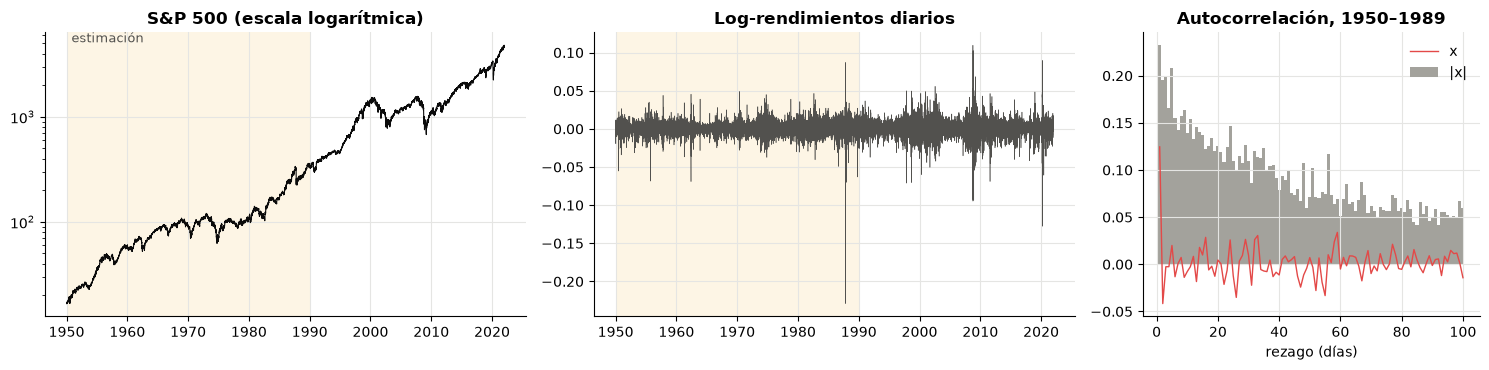

In [4]:
hasta = len(x) if EVALUAR_RESERVADO else i_res
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2, 2, 1.4]})
ax[0].plot(precio[:fechas[hasta - 1]], color="#0b0b0b", lw=0.8); ax[0].set_yscale("log")
ax[0].set_title("S&P 500 (escala logarítmica)")
ax[1].plot(fechas[:hasta], x[:hasta], color="#52514e", lw=0.4); ax[1].set_title("Log-rendimientos diarios")
for a in ax[:2]:
    a.axvspan(fechas[0], fechas[i_des], color="#eda100", alpha=0.10, lw=0)
ax[0].text(fechas[200], ax[0].get_ylim()[1], "estimación", va="top", fontsize=9, color="#52514e")
ax[2].bar(range(1, 101), acf(np.abs(x_est)), color="#a3a29c", width=1, label="|x|")
ax[2].plot(range(1, 101), acf(x_est), color="#e34948", lw=1, label="x")
ax[2].set_title("Autocorrelación, 1950–1989"); ax[2].set_xlabel("rezago (días)"); ax[2].legend()
plt.tight_layout(); plt.show()

**Lectura de los datos.**
- **Los dos tramos que se usan son muy distintos.** La curtosis de 1950–1989 (61.8) está dominada por octubre de 1987: de los 10 días que se acotan a ±6 desviaciones estándar, 5 son de octubre de 1987. La de 1990–2021 (14.4) es más típica, pero sigue muy lejos de 3. Las colas anchas no dependen de un solo evento.
- **El desarrollo es más volátil que la estimación:** desviación diaria de 1.14% contra 0.85%, es decir, 18.1% anual contra 13.5%. Un modelo que aprendiera "qué es una crisis" con 1950–1989 vería al mercado de 1990–2021 como más agitado de lo normal. Por eso el detector se reestima con datos recientes. Pero, como se verá en P2, eso tiene un costo: lo que el modelo llama "crisis" depende de la ventana.
- **La autocorrelación de los rendimientos es casi cero; la de $|x|$ es positiva y baja muy lento.** Esto justifica un modelo de regímenes de volatilidad y anticipa su límite: lo que se puede predecir es la volatilidad, no la dirección.

## A.3 El código del modelo

**Qué hacemos.** Programamos el HMM desde cero con `numpy` y `scipy`, para que cada función corresponda a una ecuación del modelo y nada sea una caja negra.

| Función | Qué hace | Fuente |
|---|---|---|
| `densidades` | Qué tan probable es cada rendimiento dentro de cada régimen, con distribución normal o t | [1], [11] |
| `forward` | **Probabilidad filtrada**: la probabilidad de cada régimen usando sólo los datos hasta ese día | [1], [2] |
| `backward` | Completa la **probabilidad suavizada**, que usa todos los datos y sirve para estimar | [1] |
| `ajustar_hmm` | Estima el modelo con el algoritmo de **Baum-Welch** | [1], [3], [11], [12] |
| `ordenar` | Ordena los regímenes de menor a mayor volatilidad, para que sus nombres no se crucen | [11] |
| `mejor_ajuste` | Estima desde varios puntos de partida y conserva el mejor | [1] |
| `viterbi` | Reconstruye la secuencia de regímenes más probable usando toda la historia: **sólo para describir el pasado** | [1], [7] |
| `pseudo_residuales` | Revisa si el modelo describe bien los datos: si sí, deben parecerse a una normal estándar (P1) | [4] |
| `simular` | Genera datos de un HMM con parámetros dados (memoria de la volatilidad, P1) | — |
| `sharpe_deflactado` | Sharpe deflactado (P5) | [14] |

**Cómo funciona Baum-Welch.** Repite dos pasos hasta que el ajuste deja de mejorar:
- **Paso E:** calcula, para cada día, la probabilidad $\gamma_i(t)$ de que el mercado estuviera en el régimen $i$.
- **Paso M:** con esas probabilidades, recalcula la media, la volatilidad y las probabilidades de cambio de cada régimen.

**Con la distribución t** (Bulla [11]), cada día recibe un peso $u_i(t) = \dfrac{\nu_i+1}{\nu_i + (x_t-\mu_i)^2/\sigma_i^2}$. Un día normal pesa cerca de uno y un día extremo cerca de cero, así que un solo día raro no arrastra la media y la volatilidad del régimen:

$$\mu_i = \dfrac{\sum_t \gamma_i(t)u_i(t)x_t}{\sum_t \gamma_i(t)u_i(t)}, \qquad \sigma_i^2 = \dfrac{\sum_t \gamma_i(t)u_i(t)(x_t-\mu_i)^2}{\sum_t \gamma_i(t)}$$

- **Con la normal**, todos los pesos valen 1.
- **Los grados de libertad** $\nu_i$ controlan qué tan anchas son las colas de la t (menos grados, más días extremos) y se limitan a $2 < \nu_i < 40$ [11].
- **Con olvido exponencial**, además, cada día pesa $\lambda^{\text{antigüedad}}$ en esas sumas [12].

In [5]:
def densidades(x, mu, sigma, nu, dist):
    """Matriz T x N: densidad de cada rendimiento bajo cada régimen (la pieza B de Rabiner [1])."""
    z = (x[:, None] - mu) / sigma
    if dist == "normal":
        return stats.norm.pdf(z) / sigma + 1e-300
    return stats.t.pdf(z, df=nu) / sigma + 1e-300


def forward(dens, A, pi):
    """Algoritmo forward con escalamiento [1] (= filtro de Hamilton [2]).
    alfa[t, i] = P(S_t = i | x_1..x_t): sólo usa información hasta el día t."""
    T, N = dens.shape
    alfa, c = np.zeros((T, N)), np.zeros(T)
    a = pi * dens[0]
    c[0] = a.sum(); alfa[0] = a / c[0]
    for t in range(1, T):
        a = (alfa[t - 1] @ A) * dens[t]
        c[t] = a.sum(); alfa[t] = a / c[t]
    return alfa, c, np.log(c).sum()


def backward(dens, A, c):
    T, N = dens.shape
    beta = np.ones((T, N))
    for t in range(T - 2, -1, -1):
        beta[t] = (A @ (dens[t + 1] * beta[t + 1])) / c[t + 1]
    return beta


def ajustar_hmm(x, N, dist="t", semilla=0, inicio=None, pesos=None, max_iter=500, tol=1e-7):
    """Baum-Welch (EM) [1], [3]. Con dist='t' usa los pesos u_i(t) de Bulla [11].
    'pesos' permite el olvido exponencial de Nystrup et al. [12] (None = todos los días pesan igual)."""
    rng = np.random.default_rng(semilla)
    w = np.ones(len(x)) if pesos is None else pesos
    if inicio is None:   # inicialización aleatoria
        sigma = np.sort(x.std() * rng.uniform(0.4, 1.6, N))
        mu = rng.normal(0, x.std() * 0.1, N)
        A = np.full((N, N), 0.04 / (N - 1)) + np.eye(N) * (0.96 - 0.04 / (N - 1))
        pi, nu = np.full(N, 1 / N), np.full(N, 8.0)
    else:                # arranque desde una estimación previa
        mu, sigma, nu, A, pi = [np.array(inicio[k], dtype=float) for k in ("mu", "sigma", "nu", "A", "pi")]
    ll_prev = -np.inf
    for it in range(max_iter):
        # Paso E: probabilidad suavizada de cada régimen (gamma) y de cada transición (xi)
        dens = densidades(x, mu, sigma, nu, dist)
        alfa, c, ll = forward(dens, A, pi)
        beta = backward(dens, A, c)
        gamma = alfa * beta
        xi = alfa[:-1, :, None] * A[None] * (dens[1:] * beta[1:])[:, None, :] / c[1:, None, None]
        # Paso M: cada parámetro es una frecuencia esperada (ponderada por día si hay olvido)
        g, xw = gamma * w[:, None], xi * w[1:, None, None]
        pi = gamma[0]
        A = xw.sum(0) / xw.sum(0).sum(1, keepdims=True)
        u = (nu + 1) / (nu + ((x[:, None] - mu) / sigma) ** 2) if dist == "t" else np.ones_like(g)   # ec. (1)
        mu = (g * u * x[:, None]).sum(0) / (g * u).sum(0)                                             # ec. (2)
        sigma = np.maximum(np.sqrt((g * u * (x[:, None] - mu) ** 2).sum(0) / g.sum(0)), 1e-4)
        if dist == "t":   # grados de libertad: maximizan la verosimilitud esperada, acotados 2 < nu < 40 [11]
            for i in range(N):
                f = lambda v: -(g[:, i] * stats.t.logpdf((x - mu[i]) / sigma[i], df=v)).sum()
                nu[i] = optimize.minimize_scalar(f, bounds=(2.1, 40), method="bounded").x
        # Convergencia [3]: el aumento relativo de la verosimilitud es menor que tol
        if abs(ll - ll_prev) < tol * abs(ll):
            break
        ll_prev = ll
    _, _, ll = forward(densidades(x, mu, sigma, nu, dist), A, pi)
    return ordenar({"mu": mu, "sigma": sigma, "nu": nu, "A": A, "pi": pi, "ll": ll, "dist": dist, "N": N, "iter": it + 1})


def ordenar(m):
    """Ordena los regímenes de menor a mayor volatilidad (identificabilidad, Bulla [11])."""
    o = np.argsort(m["sigma"] * (np.sqrt(m["nu"] / (m["nu"] - 2)) if m["dist"] == "t" else 1))
    m = dict(m)
    for k in ("mu", "sigma", "nu", "pi"):
        m[k] = m[k][o]
    m["A"] = m["A"][np.ix_(o, o)]
    return m


def mejor_ajuste(x, N, dist, n_init, semilla, pesos=None):
    """EM converge a máximos locales [1]: se estima desde varias inicializaciones y se conserva la mejor."""
    ajustes = [ajustar_hmm(x, N, dist, semilla=semilla + s, pesos=pesos) for s in range(n_init)]
    return max(ajustes, key=lambda m: m["ll"]), np.array([a["ll"] for a in ajustes])


def n_parametros(N, dist):
    return 2 * N + N * (N - 1) + (N - 1) + (N if dist == "t" else 0)   # mu, sigma, A, pi (+ nu)


def bic(m, T):
    return -2 * m["ll"] + n_parametros(m["N"], m["dist"]) * np.log(T)


def desv_estandar(m):
    """Desviación estándar diaria de cada régimen (en la t, sigma es escala y se corrige por nu)."""
    return m["sigma"] * (np.sqrt(m["nu"] / (m["nu"] - 2)) if m["dist"] == "t" else 1)


def filtrar(x, m):
    return forward(densidades(x, m["mu"], m["sigma"], m["nu"], m["dist"]), m["A"], m["pi"])[0]


def viterbi(x, m):
    """Secuencia de regímenes más probable con TODA la historia [1]: sólo para describir el pasado [7]."""
    logd = np.log(densidades(x, m["mu"], m["sigma"], m["nu"], m["dist"]))
    logA = np.log(m["A"] + 1e-300)
    T, N = logd.shape
    delta, psi = np.log(m["pi"] + 1e-300) + logd[0], np.zeros((T, N), dtype=int)
    for t in range(1, T):
        s = delta[:, None] + logA
        psi[t] = s.argmax(0); delta = s.max(0) + logd[t]
    ruta = np.zeros(T, dtype=int); ruta[-1] = delta.argmax()
    for t in range(T - 2, -1, -1):
        ruta[t] = psi[t + 1, ruta[t + 1]]
    return ruta


def pseudo_residuales(x, m):
    """Pseudo-residuales de pronóstico (Pohle et al. [4]): si el modelo ajusta, son N(0,1)."""
    alfa = filtrar(x, m)
    pred = np.vstack([m["pi"], alfa[:-1] @ m["A"]])     # P(S_t | x_1..x_{t-1})
    z = (x[:, None] - m["mu"]) / m["sigma"]
    F = stats.norm.cdf(z) if m["dist"] == "normal" else stats.t.cdf(z, df=m["nu"])
    return stats.norm.ppf(np.clip((pred * F).sum(1), 1e-10, 1 - 1e-10))


def simular(m, T, semilla):
    """Simula T días de un HMM con parámetros conocidos."""
    rng = np.random.default_rng(semilla)
    s = np.zeros(T, dtype=int); s[0] = rng.choice(m["N"], p=m["pi"])
    for t in range(1, T):
        s[t] = rng.choice(m["N"], p=m["A"][s[t - 1]])
    e = rng.standard_normal(T) if m["dist"] == "normal" else rng.standard_t(m["nu"][s])
    return m["mu"][s] + m["sigma"][s] * e, s

In [6]:
def sharpe_deflactado(ex, todas):
    """PSR y DSR de Bailey y López de Prado [14] (ecs. 4 y 5 de la investigación).
    ex: excesos diarios de la configuración reportada; todas: DataFrame con los excesos de TODAS las pruebas."""
    T, sr = len(ex), ex.mean() / ex.std()
    g3, g4 = stats.skew(ex), stats.kurtosis(ex, fisher=False)
    srs = todas.mean() / todas.std()
    M = todas.shape[1]
    corr = todas.corr().values
    rho = corr[np.triu_indices(M, 1)].mean()
    N_ef = rho + (1 - rho) * M
    gam = 0.5772156649
    sr0 = np.sqrt(srs.var()) * ((1 - gam) * stats.norm.ppf(1 - 1 / N_ef) + gam * stats.norm.ppf(1 - 1 / (N_ef * np.e)))
    den = np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)
    psr0 = stats.norm.cdf(sr * np.sqrt(T - 1) / den)
    dsr = stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / den)
    return {"Sharpe diario": sr, "Sharpe anual": sr * np.sqrt(252), "pruebas (M)": M, "correlación media": rho,
            "pruebas efectivas": N_ef, "umbral SR0 diario": sr0, "PSR (Sharpe > 0)": psr0, "DSR": dsr}

# B. El modelo (tramo de estimación, 1950–1989)

En este bloque todo se estima con 1950–1989. La pregunta es **cómo es el modelo**, no si sirve para invertir; eso se responde en el bloque C, con datos que el modelo no vio.

## P1. ¿Qué modelo usamos y cómo se ve?

**Qué esperamos.**
- **Distribución** (Bulla [11]): la t tiene colas más anchas, así que puede explicar los días extremos **dentro** de un régimen. La normal, en cambio, tiene que abrir regímenes artificiales para explicarlos (Climent Hernández et al. [8]).
- **Número de regímenes** (Pohle et al. [4]; Liu y Wang [7]): fijamos N = 3 (alcista, base y bajista) por su interpretación, con el BIC sólo como guía. Bulla encontró que, con la t, el BIC suele preferir menos regímenes; por eso no esperamos que N = 3 gane el BIC, sino que sea estable y tenga sentido económico.
- **Sentido económico** (Bulla [11]): el régimen más volátil es el de peor rendimiento, y con la t el modelo cambia de régimen muchas menos veces que con la normal.

**Qué medimos.**
1. **Selección.** Seis modelos (normal y t, con 2, 3 y 4 regímenes), cada uno desde 10 puntos de partida:
   - **BIC:** premia el buen ajuste y castiga tener más parámetros; menor es mejor.
   - **Estabilidad:** el porcentaje de puntos de partida que llegan a la mejor solución.
   - **Duración mínima:** cuántos días dura en promedio el régimen menos persistente, $1/(1-a_{ii})$. Un régimen que dura pocos días no es un régimen de mercado.
   - **Orden coincide:** si el régimen más volátil es también el de peor rendimiento.

   Con N = 3, se usa la distribución de menor BIC entre las que llegan a la mejor solución en al menos el 30% de los arranques. Los **pseudo-residuales** (Pohle et al. [4]) revisan si el modelo describe bien las colas: si sí, caen sobre la diagonal.
2. **El modelo elegido.** Rendimiento, volatilidad y duración esperada de cada régimen. Como dato de apoyo, qué parte de la **memoria de la volatilidad** reproduce: la autocorrelación media de $|x|$ simulada con el modelo entre la real. La memoria que falte es la que, según Nystrup et al. [12], deben aportar los parámetros que cambian con el tiempo (P2).
3. **Lectura descriptiva, 1950–2021.** Viterbi reconstruye qué régimen hubo cada día y fecha los episodios bajistas. Usa toda la historia, así que sirve para **describir** el pasado, no para evaluar una estrategia [7]. Esos episodios son la referencia de crisis de P2, P3 y P4.

*Esta parte tarda varios minutos.*

In [7]:
filas, modelos = [], {}
t0 = time.time()
for dist in ["normal", "t"]:
    for n_ in CONFIG["N_comparacion"]:
        m, lls = mejor_ajuste(x_est_a, n_, dist, CONFIG["n_inicializaciones"], SEM)
        modelos[(dist, n_)] = m
        filas.append({"distribución": dist, "N": n_, "parámetros": n_parametros(n_, dist), "log L": m["ll"],
                      "BIC": bic(m, len(x_est_a)), "estabilidad": np.mean(lls > m["ll"] - 1),
                      "duración mínima (días)": (1 / (1 - np.diag(m["A"]))).min(),
                      "orden coincide": bool(np.all(np.diff(m["mu"]) < 0))})
        print(f"{dist:>6} N={n_}: BIC = {filas[-1]['BIC']:,.1f}  ({time.time() - t0:,.0f} s)")
tabla_sel = pd.DataFrame(filas)
tabla_sel["ΔBIC"] = tabla_sel["BIC"] - tabla_sel["BIC"].min()

con_N = tabla_sel[(tabla_sel["N"] == N) & (tabla_sel["estabilidad"] >= 0.3)].sort_values("BIC")
DIST = con_N.iloc[0]["distribución"] if len(con_N) else "t"
OTRA = "normal" if DIST == "t" else "t"
modelo_est = modelos[(DIST, N)]
print(f"\nCon N = {N}, la distribución que se usa en adelante es: {DIST}")
tabla_sel.style.format({"log L": "{:,.1f}", "BIC": "{:,.1f}", "ΔBIC": "{:,.1f}", "estabilidad": "{:.0%}",
                        "duración mínima (días)": "{:.1f}"}).apply(
    lambda r: ["background-color: #e8f0fb" if (r["N"] == N and r["distribución"] == DIST) else "" for _ in r], axis=1)

normal N=2: BIC = -70,273.4  (14 s)
normal N=3: BIC = -70,676.3  (34 s)
normal N=4: BIC = -70,759.1  (88 s)
     t N=2: BIC = -70,497.5  (109 s)
     t N=3: BIC = -70,719.0  (162 s)
     t N=4: BIC = -70,776.9  (297 s)

Con N = 3, la distribución que se usa en adelante es: t


,distribución,N,parámetros,log L,BIC,estabilidad,duración mínima (días),orden coincide,ΔBIC
0,normal,2,7,"35,169.0","-70,273.4",100%,26.7,True,503.5
1,normal,3,14,"35,402.7","-70,676.3",90%,19.8,True,100.6
2,normal,4,23,"35,485.5","-70,759.1",20%,3.1,False,17.8
3,t,2,9,"35,290.2","-70,497.5",100%,67.4,True,279.4
4,t,3,17,"35,437.8","-70,719.0",90%,35.9,True,57.9
5,t,4,27,"35,512.9","-70,776.9",60%,3.3,False,0.0


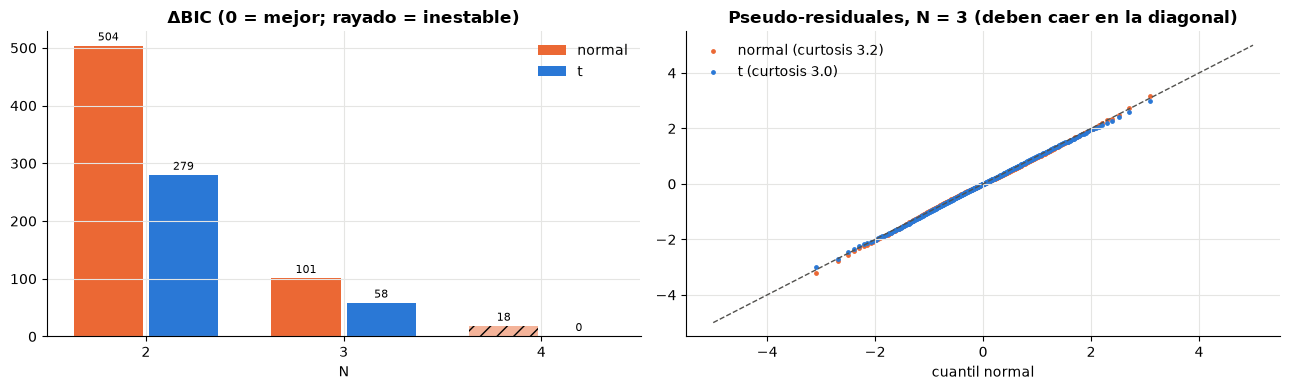

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, dist in enumerate(["normal", "t"]):
    sub = tabla_sel[tabla_sel["distribución"] == dist]
    b = ax[0].bar(sub["N"] + (j - 0.5) * 0.38, sub["ΔBIC"], 0.35, color=["#eb6834", "#2a78d6"][j], label=dist)
    ax[0].bar_label(b, labels=[f"{v:,.0f}" for v in sub["ΔBIC"]], padding=2, fontsize=8)
    for barra, est in zip(b, sub["estabilidad"] >= 0.3):
        if not est: barra.set_hatch("//"); barra.set_alpha(0.5)
ax[0].set_xticks(CONFIG["N_comparacion"]); ax[0].set_xlabel("N"); ax[0].legend()
ax[0].set_title("ΔBIC (0 = mejor; rayado = inestable)")

q = np.linspace(0.001, 0.999, 400)
for dist, col in [("normal", "#eb6834"), ("t", "#2a78d6")]:
    z = pseudo_residuales(x_est_a, modelos[(dist, N)])
    ax[1].scatter(stats.norm.ppf(q), np.quantile(z, q), s=6, color=col,
                  label=f"{dist} (curtosis {stats.kurtosis(z, fisher=False):.1f})")
ax[1].plot([-5, 5], [-5, 5], color="#52514e", ls="--", lw=1)
ax[1].set_title(f"Pseudo-residuales, N = {N} (deben caer en la diagonal)"); ax[1].set_xlabel("cuantil normal"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura de la selección.**
- **La t le gana a la normal en todos los N:** con N = 3, por 42.7 puntos de BIC (100.6 contra 57.9 de ΔBIC). Es lo que esperábamos de Bulla [11].
- **Pero el BIC no se detiene en N = 3:** la t con N = 4 tiene 57.9 puntos menos. No replicamos el hallazgo de Bulla de que con la t bastan menos regímenes. Probablemente se debe a que este tramo incluye 1987, que sigue siendo extremo aun acotado.
- **N = 4 no es un modelo utilizable:** sólo 60% de los arranques llegan a la mejor solución (20% con la normal), su régimen más corto dura 3.3 días y el orden por volatilidad deja de coincidir con el orden por rendimiento. Es decir, el cuarto régimen se usa para aislar unos cuantos días extremos, no para describir una fase del mercado. Esto confirma la advertencia de Pohle et al. [4]: el BIC sigue premiando estados extra aunque no tengan interpretación.
- **Pseudo-residuales:** con N = 3, los de las dos distribuciones caen sobre la diagonal (curtosis de 3.0 con la t y 3.2 con la normal). Una vez que los días extremos se acotan, las dos describen bien la distribución; la ventaja de la t se ve en el BIC, en la persistencia y en la memoria, no en las colas residuales.

**Decisión:** la t con N = 3. No es el modelo de menor BIC, pero es el más rico de los que son estables e interpretables.

**El modelo elegido.**

In [9]:
print(f"HMM {DIST}, N = {N}, estimado con 1950–1989")
display(tabla_regimenes(modelo_est).style.format(FMT_REG))

# Memoria de la volatilidad (dato de apoyo): autocorrelación media de |x| en los rezagos 1 a 100, simulada entre real [11], [12]
acf_dat = acf(np.abs(x_est_a))
memoria = {d: acf(np.abs(simular(modelos[(d, N)], 100_000, SEM)[0])).mean() / acf_dat.mean() for d in ["normal", "t"]}
print("Memoria de la volatilidad que reproduce cada modelo (N = 3): "
      + ", ".join(f"HMM {d} = {v:.0%}" for d, v in memoria.items()))

HMM t, N = 3, estimado con 1950–1989


,rend. anual,vol. anual,ν,a_ii,duración esperada (días)
alcista,22.7%,6.9%,12.1,0.9795,49
base,5.9%,11.9%,12.7,0.9817,55
bajista,-16.8%,22.6%,7.5,0.9721,36


Memoria de la volatilidad que reproduce cada modelo (N = 3): HMM normal = 49%, HMM t = 57%


**Lectura del modelo elegido.**
- **Dentro de muestra, los regímenes son exactamente lo que buscábamos:** alcista (+22.7% anual con 6.9% de volatilidad), base (+5.9% con 11.9%) y bajista (−16.8% con 22.6%). Ordenar por volatilidad equivale a ordenar por rendimiento, como dice Bulla [11].
- **Son persistentes:** duran en promedio 49, 55 y 36 días. El bajista es el más corto, y casi nunca pasa directo a alcista (probabilidad diaria de 0.0001): sale pasando por base.
- **ν entre 7.5 y 12.7:** todos los regímenes conservan colas más anchas que la normal, sobre todo el bajista.
- **Memoria de la volatilidad:** el modelo con la t reproduce 57% de la autocorrelación media de $|x|$, contra 49% con la normal. Mejora, pero falta 43%. Según Nystrup et al. [12], esa memoria faltante viene de parámetros que cambian con el tiempo, y P2 confirma que cambian mucho.

**Lectura descriptiva (1950–2021).** Viterbi con un modelo estimado con toda la historia hasta 2021: cuántas veces cambia de régimen con cada distribución (persistencia) y cuáles son los episodios bajistas más largos.

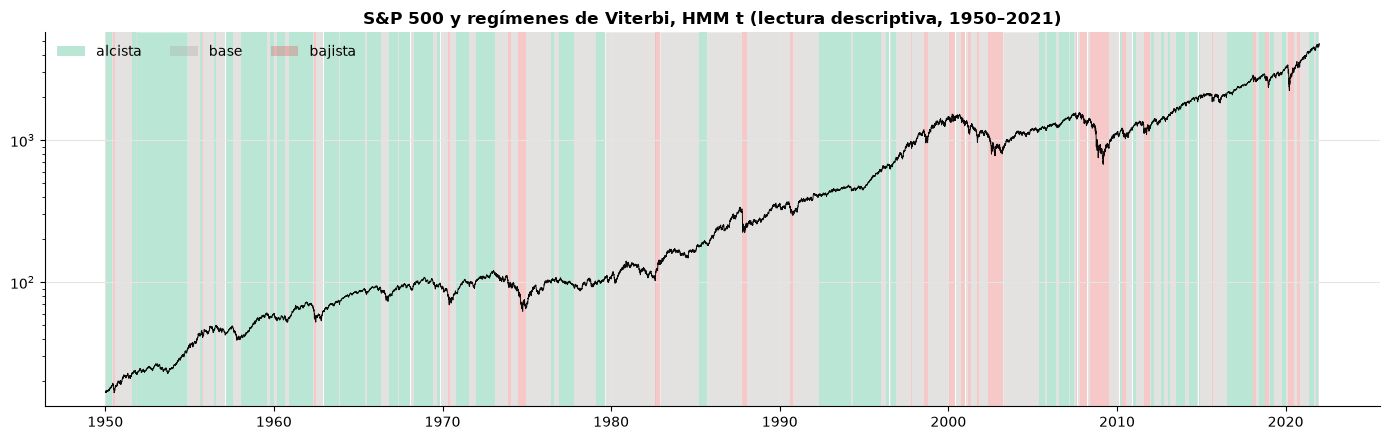

Cambios de régimen 1950–2021: HMM normal = 215, HMM t = 142
Porcentaje de días en cada régimen: {'alcista': '39%', 'base': '50%', 'bajista': '10%'}
Episodios bajistas más largos:


,inicio,fin,días,rend. del índice,vol. anual realizada
20,2008-06-05,2009-07-15,280,-32.3%,43.8%
17,2002-05-06,2003-04-02,230,-17.9%,28.3%
6,1974-06-25,1974-12-10,118,-23.3%,26.8%
13,2000-01-04,2000-06-02,105,1.5%,26.4%
19,2007-11-01,2008-04-01,103,-11.6%,24.1%
22,2011-08-02,2011-12-20,99,-3.5%,33.6%
26,2020-02-21,2020-06-30,91,-8.1%,54.1%
8,1987-10-06,1988-01-25,77,-23.1%,58.4%
7,1982-08-17,1982-11-30,74,33.1%,24.6%
14,2000-10-06,2001-01-05,63,-9.6%,27.0%


In [10]:
x_hist, f_hist = x[:i_res], fechas[:i_res]
x_hist_a = acotar_extremos(x_hist, CONFIG["acotar_extremos"])
hist = {d: mejor_ajuste(x_hist_a, N, d, 4, SEM)[0] for d in ["normal", "t"]}
rutas = {d: viterbi(x_hist, m) for d, m in hist.items()}
cambios = {d: int((np.diff(r) != 0).sum()) for d, r in rutas.items()}
ruta = pd.Series(rutas[DIST], index=f_hist)

fig, ax = plt.subplots(figsize=(14, 4.5))
p = precio.reindex(f_hist)
ax.plot(p, color="#0b0b0b", lw=0.7); ax.set_yscale("log")
for i, n in enumerate(NOMBRES):
    ax.fill_between(f_hist, p.min() * 0.8, p.max() * 1.2, where=(ruta == i).values, color=C_REG[n], alpha=0.30, lw=0, label=n)
ax.set_ylim(p.min() * 0.8, p.max() * 1.2); ax.legend(loc="upper left", ncol=3)
ax.set_title(f"S&P 500 y regímenes de Viterbi, HMM {DIST} (lectura descriptiva, {f_hist[0]:%Y}–{f_hist[-1]:%Y})")
plt.tight_layout(); plt.show()

reg_v, largo_v = corridas(ruta.values)
ini_v = np.r_[0, np.cumsum(largo_v)[:-1]]
episodios = pd.DataFrame([{"inicio": f_hist[a], "fin": f_hist[a + l - 1], "días": l,
                           "rend. del índice": precio[f_hist[a + l - 1]] / precio.asof(f_hist[a] - pd.Timedelta(days=1)) - 1,
                           "vol. anual realizada": x_serie.iloc[a:a + l].std() * np.sqrt(252)}
                          for r_, a, l in zip(reg_v, ini_v, largo_v) if r_ == N - 1])
print(f"Cambios de régimen 1950–2021: HMM normal = {cambios['normal']}, HMM t = {cambios['t']}")
print("Porcentaje de días en cada régimen:", {n: f"{(ruta == i).mean():.0%}" for i, n in enumerate(NOMBRES)})
print("Episodios bajistas más largos:")
episodios.sort_values("días", ascending=False).head(10).style.format(
    {"inicio": "{:%Y-%m-%d}", "fin": "{:%Y-%m-%d}", "rend. del índice": "{:.1%}", "vol. anual realizada": "{:.1%}"})

**Lectura descriptiva.**
- **Persistencia:** de 1950 a 2021, Viterbi cuenta 142 cambios de régimen con la t contra 215 con la normal (−34%). La dirección es la de Bulla, aunque la reducción es menor que la suya (de 41 a 5), porque aquí ambos modelos tienen N = 3 y los extremos ya están acotados.
- **Las fechas tienen sentido:** los episodios bajistas más largos son 2008–2009, 2002–2003, 1974, 2007–2008, 2011, 2020 y 1987.
- **Primera señal del problema central:** el régimen bajista se define por volatilidad, no por pérdidas. En el episodio de 1982 (agosto a noviembre), el índice **subió 33.1%**, y en el de enero a junio de 2000 subió 1.5%. Son periodos agitados al alza. El modelo los llama "bajistas" porque son volátiles, y la regla de inversión los trataría como crisis.

> **Respuesta a P1.** La t con N = 3 describe bien 1950–1989: le gana a la normal en el BIC, es estable, sus regímenes duran semanas y se ordenan igual por volatilidad que por rendimiento. Matices: (i) el BIC preferiría N = 4, que no es interpretable; (ii) el modelo sólo reproduce la mitad de la memoria de la volatilidad; (iii) "bajista" significa "volátil", y eso no siempre coincide con "pierde".

# C. El detector en tiempo real (tramo de desarrollo, 1990–2021)

A partir de aquí el modelo se usa **como lo habría usado un inversionista**: cada decisión se toma sólo con la información disponible ese día.

## C.1 Prueba en tiempo real

**Cómo funciona.**
1. Cada 21 días hábiles (un mes), el modelo se vuelve a estimar sólo con datos anteriores, con los días extremos recortados como en A.2.
2. Con esos parámetros se calcula cada día la **probabilidad filtrada** de cada régimen, que sólo usa los rendimientos hasta ese día (Liu y Wang [7]). Para esto se usan los rendimientos originales, sin recortar.
3. En cada reestimación se guardan los parámetros de cada régimen, incluidos los grados de libertad ν.
4. También se guarda qué régimen era el más probable **el día anterior** con los parámetros viejos y con los nuevos, con los mismos datos. Si no coinciden, la etiqueta cambió sólo por reestimar (P2).

**Variantes que corren a la vez.** Cada una cambia **una sola cosa** respecto al detector principal, para medir cuánto aporta esa decisión:

| Variante | Qué cambia | Para qué | Se reestima cada | Se reporta en |
|---|---|---|---|---|
| **Principal** | — (distribución de P1, N = 3, últimos 2,000 días [9]) | El detector | 21 días | P2 a P5 |
| N = 2 | Dos regímenes en lugar de tres | ¿Cuesta desempeño la explicabilidad de N = 3? | 21 días | P2, P4 |
| Olvido exponencial | Más historia, con menos peso a los días viejos | ¿Parámetros más suaves? [12] | 21 días | P2, P4 |
| Otra distribución | Normal en lugar de t (o al revés) | Ya se probó en P1 | 21 días | sólo bitácora (P5) |
| Ventanas de 1,000, 2,000 y 3,000 días | Cuánta historia se usa | Ya se probó en la v4 | 63 días | sólo bitácora (P5) |

**Olvido exponencial** (Nystrup et al. [12]). En lugar de usar sólo los últimos 2,000 días, todos con el mismo peso, usa 6,000 días, y cada uno pesa $\lambda^{\text{antigüedad}}$ con λ = 0.9995. Es como tener una memoria de unos 2,000 días, igual que la ventana, pero los días viejos van perdiendo peso poco a poco en lugar de salir de golpe.

*Es la parte más lenta del notebook (unos 30 minutos).*

In [11]:
def prueba_movil(dist, n_reg, inicio, fin, W, R, olvido=None):
    largo = W if olvido is None else 3 * W                       # con olvido: más historia, pesada por antigüedad
    pesos = None if olvido is None else olvido ** np.arange(largo - 1, -1, -1)
    nombres = nombres_regimen(n_reg)
    prob, registro, m = np.full((fin - inicio, n_reg), np.nan), [], None
    for r in range(inicio, fin, R):
        datos = acotar_extremos(x[r - largo:r], CONFIG["acotar_extremos"])   # sólo datos ANTERIORES al día r
        if m is None:
            candidatos = [ajustar_hmm(datos, n_reg, dist, semilla=SEM + s, pesos=pesos) for s in range(CONFIG["n_inicializaciones"])]
        else:
            candidatos = [ajustar_hmm(datos, n_reg, dist, inicio=m, pesos=pesos)]
            if (r - inicio) % CONFIG["reinicios_cada"] < R:       # arranques aleatorios extra cada 6 meses [1]
                candidatos += [ajustar_hmm(datos, n_reg, dist, semilla=SEM + r + s, pesos=pesos) for s in range(2)]
        m = max(candidatos, key=lambda c: c["ll"])
        # Salto de etiqueta (P2): el día anterior, con los MISMOS datos, ¿cambia el régimen más probable sólo por reestimar?
        salto = np.nan
        if r > inicio:
            antes = int(np.argmax(prob[r - inicio - 1]))                        # lo que el detector tenía ese día
            despues = int(np.argmax(filtrar(x[r - largo:r], m)[-1]))            # lo mismo, con los parámetros nuevos
            salto = float(antes != despues)
        hasta = min(r + R, fin)
        prob[r - inicio:hasta - inicio] = filtrar(x[r - largo:hasta], m)[largo:]
        registro.append({"fecha": fechas[r],
                         **{f"vol {n}": v for n, v in zip(nombres, desv_estandar(m) * np.sqrt(252))},
                         **{f"rend {n}": v for n, v in zip(nombres, m["mu"] * 252)},
                         **{f"ν {n}": v for n, v in zip(nombres, m["nu"] if dist == "t" else [np.nan] * n_reg)},
                         "orden coincide": bool(np.all(np.diff(m["mu"]) < 0)),
                         "bajista con la menor media": bool(np.argmin(m["mu"]) == n_reg - 1),
                         "salto de etiqueta": salto,
                         **{f"A {i}{j}": m["A"][i, j] for i in range(n_reg) for j in range(n_reg)}})   # v5.1: para el modelo B
    return (pd.DataFrame(prob, index=fechas[inicio:fin], columns=nombres),
            pd.DataFrame(registro).set_index("fecha"))


fin_prueba = len(x) if EVALUAR_RESERVADO else i_res              # bloqueado: NO se calcula nada del reservado
W0, R0, RS = CONFIG["ventana"], CONFIG["reestimar_cada"], CONFIG["reestimar_sensibilidad"]
PRINCIPAL, V_N2 = f"{DIST} | N=3 | W={W0}", f"{DIST} | N=2 | W={W0}"
V_OTRA, V_OLV = f"{OTRA} | N=3 | W={W0}", f"{DIST} | N=3 | olvido {CONFIG['olvido']}"
VARIANTES = {PRINCIPAL: (DIST, 3, W0, R0, None), V_N2: (DIST, 2, W0, R0, None),
             V_OTRA: (OTRA, 3, W0, R0, None), V_OLV: (DIST, 3, W0, R0, CONFIG["olvido"])}
for w_ in CONFIG["ventanas_sensibilidad"]:
    VARIANTES[f"{DIST} | N=3 | W={w_} | R={RS}"] = (DIST, 3, w_, RS, None)

prob, params = {}, {}
for nombre, (dist, n_reg, w_, r_, olv) in VARIANTES.items():
    t0 = time.time()
    prob[nombre], params[nombre] = prueba_movil(dist, n_reg, i_des, fin_prueba, w_, r_, olv)
    print(f"HMM {nombre:<32} {len(params[nombre]):>4} reestimaciones en {(time.time() - t0) / 60:5.1f} min")

HMM t | N=3 | W=2000                  384 reestimaciones en   3.9 min
HMM t | N=2 | W=2000                  384 reestimaciones en   2.3 min
HMM normal | N=3 | W=2000             384 reestimaciones en   2.2 min
HMM t | N=3 | olvido 0.9995           384 reestimaciones en  14.0 min
HMM t | N=3 | W=1000 | R=63           128 reestimaciones en   2.8 min
HMM t | N=3 | W=2000 | R=63           128 reestimaciones en   2.8 min
HMM t | N=3 | W=3000 | R=63           128 reestimaciones en   3.4 min


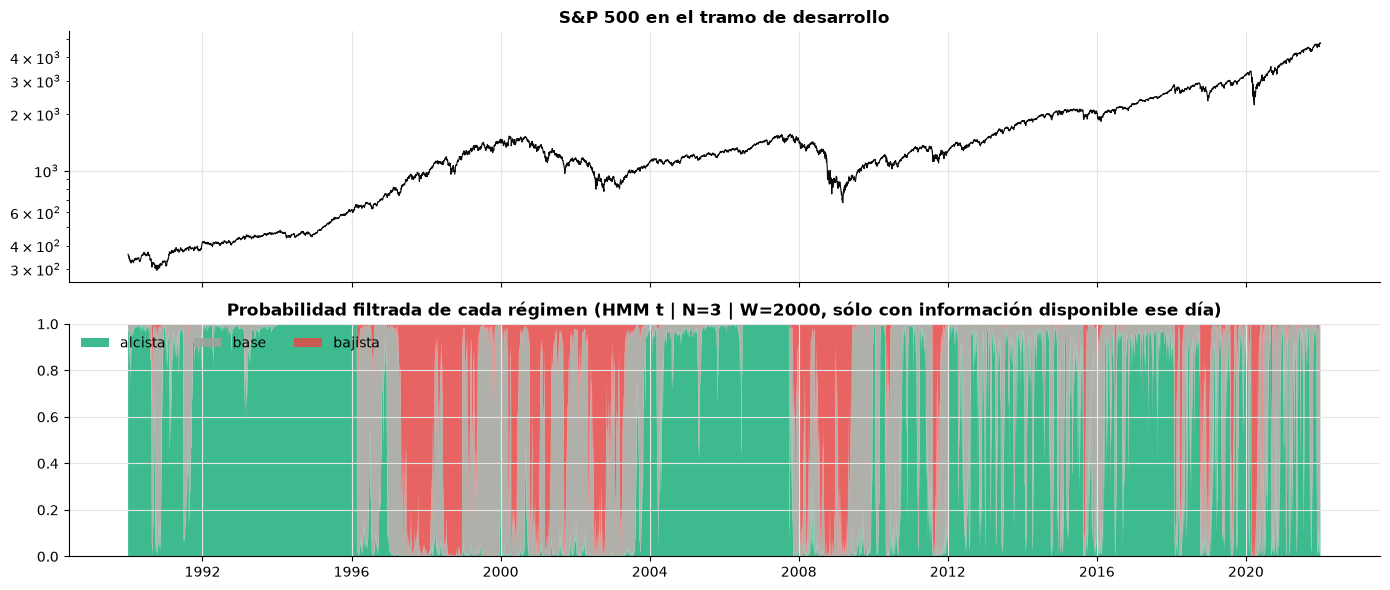

In [12]:
pd_des = prob[PRINCIPAL][:fechas[i_res - 1]]
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.3]})
ax[0].plot(precio.reindex(pd_des.index), color="#0b0b0b", lw=0.8); ax[0].set_yscale("log")
ax[0].set_title("S&P 500 en el tramo de desarrollo")
ax[1].stackplot(pd_des.index, pd_des.T.values, colors=[C_REG[n] for n in NOMBRES], labels=NOMBRES, alpha=0.85, lw=0)
ax[1].set_ylim(0, 1); ax[1].legend(loc="upper left", ncol=3)
ax[1].set_title(f"Probabilidad filtrada de cada régimen (HMM {PRINCIPAL}, sólo con información disponible ese día)")
plt.tight_layout(); plt.show()

**Lectura de la probabilidad filtrada.** La gráfica anticipa casi todo lo que sigue:
- **1990–1995:** casi siempre alcista. La ventana todavía contenía 1987, así que el régimen bajista estaba calibrado para volatilidades muy altas (cerca de 42%).
- **1996–2003:** domina el bajista o el base, **incluido el mercado alcista de 1996 a 1999**, cuando el índice más que se duplicó. Para entonces 1987 ya había salido de la ventana, que sólo contenía años tranquilos. Una volatilidad moderada bastaba para ser "bajista".
- **2003–2007:** alcista; **2008–2009:** bajista, bien identificado.
- **2010–2021:** casi siempre alcista, pero con muchos parpadeos breves hacia base. Cada parpadeo saca al detector del mercado por unos días.

## P2. ¿Los regímenes son estables en tiempo real?

**Por qué es la pregunta central.** La regla de inversión supone que "bajista" significa lo mismo en cada reestimación. Si los parámetros cambian, la etiqueta también puede cambiar, y la estrategia cambia de posición sin que el mercado haya cambiado. Esto es lo que el cambio propuesto para el Reporte 5 debe reducir.

**Qué esperamos** (Nystrup et al. [12]). Los parámetros cambian según el periodo con que se estimen; el olvido exponencial los mueve con más suavidad que la ventana.

**Qué medimos**, para el detector principal, el olvido exponencial y N = 2:
1. **Cuánto cambian los parámetros:**
   - **Orden coincide:** porcentaje de reestimaciones en que el rendimiento estimado va de mayor a menor (alcista, base y bajista).
   - **Bajista con la menor media:** porcentaje de reestimaciones en que el régimen más volátil es el de peor rendimiento. Es la condición que más importa para la regla.
   - **Volatilidad del régimen bajista:** mínima, mediana y máxima, y el **salto promedio** de una reestimación a la siguiente (menor es más suave).
   - **ν del régimen bajista:** si se acerca a 2, la volatilidad del régimen, $\sigma\sqrt{\nu/(\nu-2)}$, se dispara.
2. **Cuánto de la señal se mueve por reestimar** (nuevo):
   - **Salto de etiqueta:** porcentaje de reestimaciones en que el régimen más probable del día anterior cambia sólo por cambiar los parámetros, con los mismos datos.
   - **Cambios de posición cerca de una reestimación:** porcentaje de los cambios de posición que ocurren en los primeros k = 3 días después de reestimar (con la confirmación de 3 días, un salto de etiqueta se convierte en cambio de posición justo en ese lapso). Si reestimar no influyera, sería k/21 ≈ 14%. La **razón** observado entre esperado mide cuánto se concentran; los **cambios atribuibles** son el exceso sobre lo esperado.
3. **Dónde se pierde el orden** (nuevo). El orden coincide según:
   - **el momento de la reestimación:** dentro de un episodio bajista de Viterbi (P1), en los 6 meses después de uno o en calma;
   - **cuántos días de crisis contiene la ventana de 2,000 días**, en tercios.

   Si el orden se pierde cuando la ventana tiene pocas crisis, el régimen "bajista" es relativo a la ventana: sólo es el menos tranquilo de esos 2,000 días.

,reestimaciones,orden coincide,bajista con la menor media,vol. bajista mín.,vol. bajista mediana,vol. bajista máx.,salto promedio,ν bajista mín.,ν bajista mediana
"Detector N = 3 (ventana 2,000)",384,65%,91%,16%,34%,54%,0.7%,5.0,12.8
N = 3 con olvido,384,58%,100%,22%,29%,56%,0.5%,4.9,11.5
N = 2,384,84%,84%,14%,26%,41%,0.3%,3.7,5.5


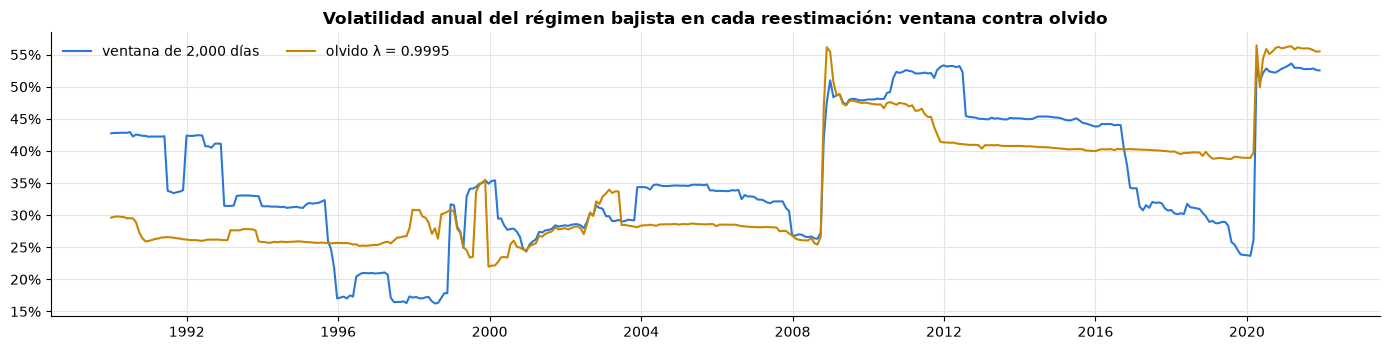

In [13]:
def resumen_estabilidad(pr):
    vb = pr["vol bajista"]
    fila = {"reestimaciones": len(pr), "orden coincide": pr["orden coincide"].mean(),
            "bajista con la menor media": pr["bajista con la menor media"].mean(),
            "vol. bajista mín.": vb.min(), "vol. bajista mediana": vb.median(), "vol. bajista máx.": vb.max(),
            "salto promedio": vb.diff().abs().mean()}
    if "ν bajista" in pr and pr["ν bajista"].notna().any():
        fila.update({"ν bajista mín.": pr["ν bajista"].min(), "ν bajista mediana": pr["ν bajista"].median()})
    return fila


REPORTADAS = {PRINCIPAL: "Detector N = 3 (ventana 2,000)", V_OLV: "N = 3 con olvido", V_N2: "N = 2"}
estab = pd.DataFrame({e: resumen_estabilidad(params[n][:fechas[i_res - 1]]) for n, e in REPORTADAS.items()}).T
display(estab.style.format({"reestimaciones": "{:.0f}", "orden coincide": "{:.0%}", "bajista con la menor media": "{:.0%}",
                            "vol. bajista mín.": "{:.0%}", "vol. bajista mediana": "{:.0%}", "vol. bajista máx.": "{:.0%}",
                            "salto promedio": "{:.1%}", "ν bajista mín.": "{:.1f}", "ν bajista mediana": "{:.1f}"}, na_rep="—"))

fig, ax = plt.subplots(figsize=(14, 3.6))
for nombre, col, lab in [(PRINCIPAL, "#2a78d6", "ventana de 2,000 días"), (V_OLV, "#c98500", f"olvido λ = {CONFIG['olvido']}")]:
    ax.plot(params[nombre][:fechas[i_res - 1]]["vol bajista"], color=col, lw=1.5, label=lab)
ax.set_title("Volatilidad anual del régimen bajista en cada reestimación: ventana contra olvido")
ax.yaxis.set_major_formatter(pct); ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

**Lectura: cuánto cambian los parámetros.**
- **La volatilidad del régimen bajista va de 16% a 54%** con la ventana de 2,000 días. Con una escala que cambia tanto, "bajista" no tiene un significado fijo. Su punto más bajo (16–17%, de 1996 a 1999) es **menor que la volatilidad promedio del índice en el desarrollo (18.1%)**: en esos años, un mercado normal ya se clasificaba como bajista.
- **La gráfica muestra escalones, no ruido.** La volatilidad bajista se mueve por saltos grandes cuando una crisis entra a la ventana o sale de ella: en 1996 sale 1987, en 2008 entra la crisis financiera, en 2016 sale y en 2020 entra el COVID. Entre esos saltos es casi constante: el salto promedio entre reestimaciones es de sólo 0.7%.
- **El olvido exponencial suaviza poco y no resuelve el problema:** el salto promedio baja de 0.7% a 0.5% y en 1996–1999 mantiene la volatilidad bajista en 25–30% (en lugar de 17%), porque conserva algo de memoria de 1987. Pero el orden coincide menos (58% contra 65%). Lo que sí mejora es que el bajista siempre es el de menor media (100% contra 91%).
- **N = 2 es más estable:** el orden coincide en 84% de las reestimaciones y sus parámetros saltan menos (0.3%). Con dos regímenes hay menos margen para que se crucen las etiquetas.

### ¿Cuánto de la señal se mueve sólo por reestimar?

,reestimaciones,salto de etiqueta,cambios de posición,% cerca de una reestimación,% esperado sin efecto,razón observado / esperado,cambios atribuibles a reestimar
"Detector N = 3 (ventana 2,000)",384,4%,177,14%,14%,0.9,-1
N = 3 con olvido,384,2%,173,10%,14%,0.7,-7
N = 2,384,1%,75,16%,14%,1.1,1


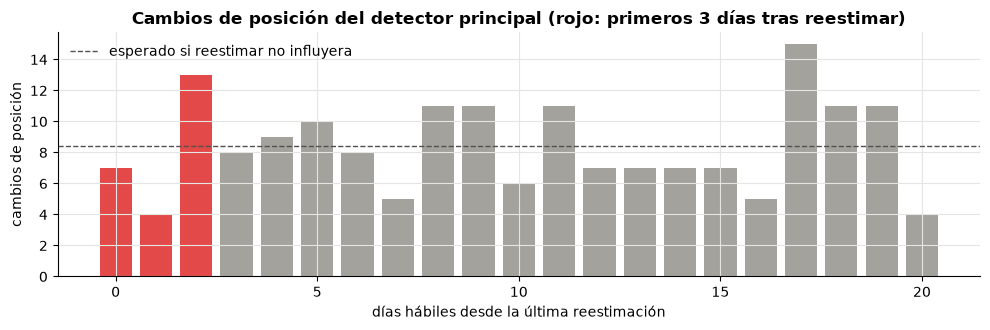

In [14]:
POS = np.array([CONFIG["posicion"][n] for n in NOMBRES])
POS2 = np.array([CONFIG["posicion"]["alcista"], CONFIG["posicion"]["bajista"]])   # N = 2: calma = alcista, turbulencia = bajista
sin_corto = lambda p: np.where(p < 0, 0.0, p)


def posicion_detector(p, k=CONFIG["dias_confirmacion"], posiciones=None):
    # Régimen más probable cada día; la posición cambia sólo si se sostiene k días seguidos [9]
    posiciones = (POS if p.shape[1] == 3 else POS2) if posiciones is None else posiciones
    mas_probable = p.values.argmax(1)
    w = np.zeros(len(mas_probable)); actual = posiciones[mas_probable[0]]
    for t in range(len(mas_probable)):
        if t >= k - 1 and np.all(mas_probable[t - k + 1:t + 1] == mas_probable[t]):
            actual = posiciones[mas_probable[t]]
        w[t] = actual
    return pd.Series(w, index=p.index)


k_conf = CONFIG["dias_confirmacion"]


def desfase_reestimacion(indice, pr):
    # Días hábiles transcurridos desde la última reestimación, para cada día de 'indice'
    i_dia, i_re = fechas.get_indexer(indice), fechas.get_indexer(pr.index)
    return i_dia - i_re[np.searchsorted(i_re, i_dia, side="right") - 1], int(np.median(np.diff(i_re)))


def efecto_reestimacion(nombre):
    pr = params[nombre][:fechas[i_res - 1]]
    w = posicion_detector(prob[nombre])[:fechas[i_res - 1]]
    cambio = w.diff().fillna(0).ne(0).values
    desfase, R = desfase_reestimacion(w.index, pr)
    cerca, esperado = (cambio & (desfase < k_conf)).sum(), k_conf / R
    return {"reestimaciones": len(pr), "salto de etiqueta": pr["salto de etiqueta"].mean(),
            "cambios de posición": int(cambio.sum()), "% cerca de una reestimación": cerca / max(cambio.sum(), 1),
            "% esperado sin efecto": esperado, "razón observado / esperado": cerca / max(cambio.sum(), 1) / esperado,
            "cambios atribuibles a reestimar": cerca - esperado * cambio.sum()}


efecto = pd.DataFrame({e: efecto_reestimacion(n) for n, e in REPORTADAS.items()}).T
display(efecto.style.format({"reestimaciones": "{:.0f}", "salto de etiqueta": "{:.0%}", "cambios de posición": "{:.0f}",
                             "% cerca de una reestimación": "{:.0%}", "% esperado sin efecto": "{:.0%}",
                             "razón observado / esperado": "{:.1f}", "cambios atribuibles a reestimar": "{:.0f}"}))

# Distribución de los cambios de posición del detector principal según los días desde la última reestimación
w_p = posicion_detector(prob[PRINCIPAL])[:fechas[i_res - 1]]
desf_p, R_p = desfase_reestimacion(w_p.index, params[PRINCIPAL][:fechas[i_res - 1]])
conteo = pd.Series(desf_p[w_p.diff().fillna(0).ne(0).values]).value_counts().reindex(range(R_p), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(conteo.index, conteo.values, color=["#e34948" if d < k_conf else "#a3a29c" for d in conteo.index], width=0.8)
ax.axhline(conteo.sum() / R_p, color="#52514e", ls="--", lw=1, label="esperado si reestimar no influyera")
ax.set_xlabel("días hábiles desde la última reestimación"); ax.set_ylabel("cambios de posición")
ax.set_title(f"Cambios de posición del detector principal (rojo: primeros {k_conf} días tras reestimar)"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura: la reestimación no es una fuente de ruido.** Es el resultado nuevo más importante de esta versión, y es negativo:
- **El régimen más probable cambia sólo por reestimar en 4% de las reestimaciones** (2% con olvido y 1% con N = 2).
- **Los cambios de posición no se concentran después de reestimar:** 14% caen en los 3 días siguientes, exactamente lo que se esperaría por azar (razón de 0.9). En la gráfica, los días 0 y 1 están por debajo de lo esperado y el día 2 por encima; en conjunto, 24 cambios contra unos 25 esperados. Los "cambios atribuibles" salen negativos (−1 y −7): no hay exceso.

**Implicación para el diseño.** Habíamos planteado que la ventana dura mete ruido en cada reestimación y que un filtro que suavizara los parámetros lo corregiría. Los datos no lo apoyan: la señal no se mueve por reestimar. Lo que cambia es el **nivel** de los parámetros cuando entra o sale una crisis de la ventana, y eso lo mide la siguiente sección.

### ¿Dónde se pierde el orden de los regímenes?

Detector principal, según el momento de la reestimación:


,reestimaciones,días bajistas en la ventana,orden coincide,bajista con la menor media,vol. bajista mediana,salto de etiqueta
en episodio bajista,69,21%,78%,93%,30%,1%
6 meses después de uno,76,13%,72%,89%,31%,7%
calma,239,11%,59%,91%,34%,3%


Detector principal, según cuántos días de crisis contiene la ventana de 2,000 días:


,reestimaciones,días bajistas en la ventana,orden coincide,bajista con la menor media,vol. bajista mediana,salto de etiqueta
pocas crisis,128,7%,9%,73%,31%,5%
intermedio,128,13%,86%,100%,32%,5%
muchas crisis,128,28%,100%,100%,45%,2%


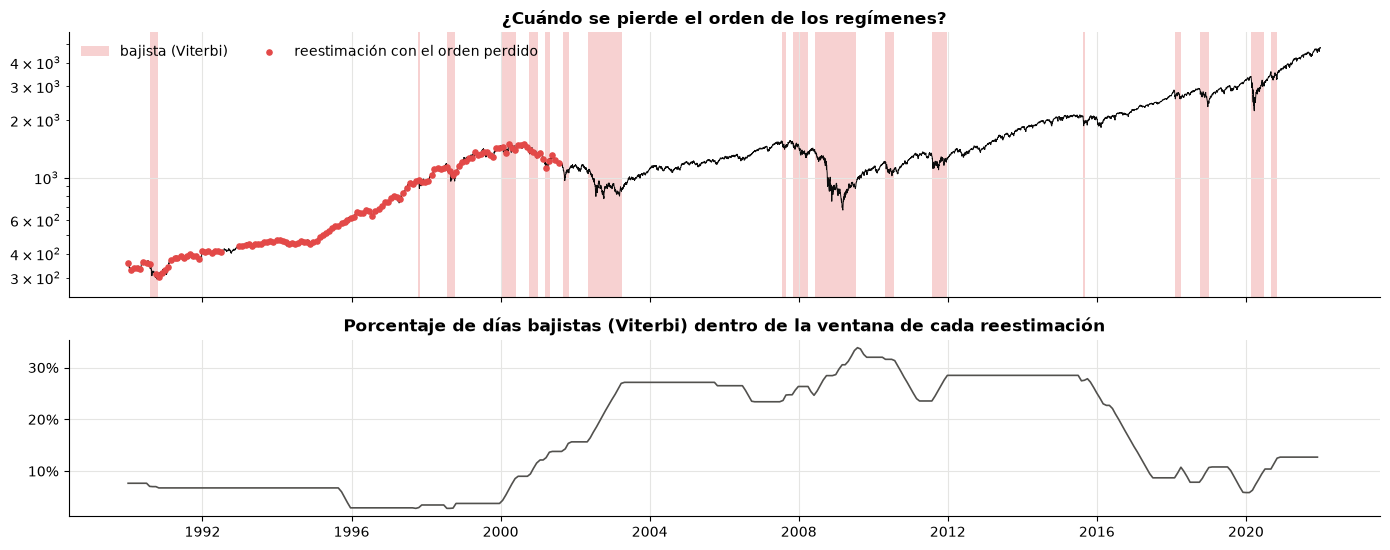

In [15]:
pr_p = params[PRINCIPAL][:fechas[i_res - 1]].copy()
i_re = fechas.get_indexer(pr_p.index)
ep_largos = episodios[episodios["días"] >= CONFIG["dias_min_episodio"]]
fin_ep = f_hist.get_indexer(ep_largos["fin"])
bajista_viterbi = ruta.values == N - 1


def momento(i):
    if bajista_viterbi[i]:
        return "en episodio bajista"
    if np.any((i - fin_ep > 0) & (i - fin_ep <= 126)):
        return "6 meses después de uno"
    return "calma"


pr_p["momento"] = [momento(i) for i in i_re]
pr_p["crisis en la ventana"] = [bajista_viterbi[i - W0:i].mean() for i in i_re]     # % de días bajistas (Viterbi) en la ventana
pr_p["tercio"] = pd.qcut(pr_p["crisis en la ventana"].rank(method="first"), 3,
                         labels=["pocas crisis", "intermedio", "muchas crisis"])


def resumen_grupo(g):
    return {"reestimaciones": len(g), "días bajistas en la ventana": g["crisis en la ventana"].median(),
            "orden coincide": g["orden coincide"].mean(), "bajista con la menor media": g["bajista con la menor media"].mean(),
            "vol. bajista mediana": g["vol bajista"].median(), "salto de etiqueta": g["salto de etiqueta"].mean()}


FMT_GR = {"reestimaciones": "{:.0f}", "días bajistas en la ventana": "{:.0%}", "orden coincide": "{:.0%}",
          "bajista con la menor media": "{:.0%}", "vol. bajista mediana": "{:.0%}", "salto de etiqueta": "{:.0%}"}
por_momento = pd.DataFrame({k: resumen_grupo(g) for k, g in pr_p.groupby("momento")}).T
por_momento = por_momento.reindex([k for k in ["en episodio bajista", "6 meses después de uno", "calma"] if k in por_momento.index])
por_ventana = pd.DataFrame({k: resumen_grupo(g) for k, g in pr_p.groupby("tercio", observed=True)}).T
print("Detector principal, según el momento de la reestimación:"); display(por_momento.style.format(FMT_GR))
print("Detector principal, según cuántos días de crisis contiene la ventana de 2,000 días:"); display(por_ventana.style.format(FMT_GR))

fig, ax = plt.subplots(2, 1, figsize=(14, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
p_des = precio.reindex(pr_p.index.union(prob[PRINCIPAL][:fechas[i_res - 1]].index))
ax[0].plot(p_des, color="#0b0b0b", lw=0.7); ax[0].set_yscale("log")
r_des = ruta.reindex(p_des.index)
ax[0].fill_between(p_des.index, p_des.min() * 0.8, p_des.max() * 1.2, where=(r_des == N - 1).values, color=C_REG["bajista"], alpha=0.25, lw=0,
                   label="bajista (Viterbi)")
mal = pr_p.index[~pr_p["orden coincide"].astype(bool)]
ax[0].scatter(mal, precio.reindex(mal), s=14, color="#e34948", zorder=3, label="reestimación con el orden perdido")
ax[0].set_ylim(p_des.min() * 0.8, p_des.max() * 1.2); ax[0].legend(loc="upper left", ncol=2)
ax[0].set_title("¿Cuándo se pierde el orden de los regímenes?")
ax[1].plot(pr_p["crisis en la ventana"], color="#52514e", lw=1.2)
ax[1].set_title("Porcentaje de días bajistas (Viterbi) dentro de la ventana de cada reestimación"); ax[1].yaxis.set_major_formatter(pct)
plt.tight_layout(); plt.show()

**Lectura: el orden se pierde cuando la ventana no contiene crisis.** Es el hallazgo central de P2:
- **Por contenido de la ventana, la diferencia es enorme.** Cuando la ventana tiene pocas crisis (mediana de 7% de días bajistas), el orden coincide en **9%** de las reestimaciones y el bajista es el de menor media en 73%. Con una cantidad intermedia (13%) sube a 86% y 100%; con muchas (28%), a 100% y 100%.
- **Por el momento de la reestimación, la diferencia es menor** (78% dentro de una crisis, 72% después y 59% en calma), y se explica por lo mismo: en calma la ventana suele tener menos crisis.
- **La gráfica muestra que la pérdida del orden es casi exclusiva de 1990–2001:** los puntos rojos ocupan esa década y prácticamente desaparecen después. El 65% global es, en realidad, "una década mala y dos buenas".

**El mecanismo.** El modelo siempre reparte los 2,000 días en tres regímenes ordenados por volatilidad. Si la ventana no tiene una crisis, el régimen "bajista" es simplemente el **menos tranquilo de esos días**, sin una media claramente negativa. Las etiquetas son **relativas a la ventana**, no absolutas. El mismo mecanismo funciona al revés: en 1990 la ventana contenía 1987, el bajista exigía 42% de volatilidad, y la corrección de 1990 (−12%, con 23% de volatilidad) no se detectó (P3).

> **Respuesta a P2.** Los parámetros cambian mucho (la volatilidad bajista va de 16% a 54%), pero no por ruido de la reestimación. Cambian por escalones, cuando una crisis entra o sale de la ventana. El problema no es la inestabilidad entre reestimaciones, sino que **la escala de los regímenes la fija la ventana**: sin crisis en la ventana, "bajista" deja de significar crisis. El olvido exponencial suaviza los saltos, pero no ancla la escala.

## P3. ¿Qué tan rápido detecta?

**Qué esperamos** (Liu y Wang [7]). La probabilidad filtrada sólo ve el pasado, así que necesita varios días de datos para convencerse de que empezó un régimen nuevo: detecta **con retraso**.

**Qué medimos.**
- **Referencia:** los episodios bajistas de al menos 20 días que fecha Viterbi en P1, con toda la historia.
- **Retraso:** para cada episodio, cuántos días hábiles pasan desde que empieza hasta que el detector principal, con sus 3 días de confirmación, se pone en posición bajista. Si no lo hace antes de que el episodio termine, el episodio cuenta como *no detectado*.
- **Coincidencia diaria:** porcentaje de días en que el detector y Viterbi señalan el mismo régimen.

Episodios detectados: 13 de 16 | retraso mediano: 5 días hábiles | coincidencia diaria con Viterbi: 63%


,inicio,fin,días,rend. del índice,vol. anual realizada,detectado,retraso (días hábiles)
10,1990-08-02,1990-10-19,56,-12.1%,22.9%,False,—
12,1998-07-21,1998-10-15,62,-11.5%,32.3%,True,0
13,2000-01-04,2000-06-02,105,1.5%,26.4%,True,52
14,2000-10-06,2001-01-05,63,-9.6%,27.0%,True,7
15,2001-03-09,2001-04-25,33,-2.8%,33.3%,True,3
16,2001-09-06,2001-11-01,37,-4.2%,27.7%,True,5
17,2002-05-06,2003-04-02,230,-17.9%,28.3%,True,4
18,2007-07-24,2007-08-29,27,-5.0%,24.9%,False,—
19,2007-11-01,2008-04-01,103,-11.6%,24.1%,True,18
20,2008-06-05,2009-07-15,280,-32.3%,43.8%,True,25


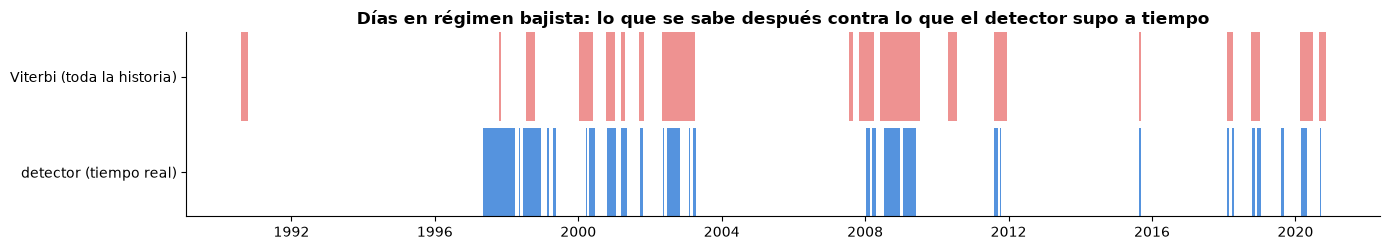

In [16]:
w_dec = posicion_detector(prob[PRINCIPAL])[:fechas[i_res - 1]]      # posición decidida (antes del rezago)
bajista_det = (w_dec == POS[-1])
ruta_des = ruta.reindex(w_dec.index)
ep_des = episodios[(episodios["inicio"] >= w_dec.index[0]) & (episodios["días"] >= CONFIG["dias_min_episodio"])].copy()
retrasos = []
for _, e in ep_des.iterrows():
    tramo = bajista_det[e["inicio"]:e["fin"]]
    retrasos.append(int(np.argmax(tramo.values)) if tramo.any() else np.nan)
ep_des["detectado"] = ~np.isnan(retrasos)
ep_des["retraso (días hábiles)"] = retrasos

coincide = (pd_des.values.argmax(1) == ruta_des.values).mean()
print(f"Episodios detectados: {ep_des['detectado'].sum()} de {len(ep_des)} | retraso mediano: "
      f"{np.nanmedian(retrasos) if len(ep_des) else np.nan:.0f} días hábiles | "
      f"coincidencia diaria con Viterbi: {coincide:.0%}")
display(ep_des.sort_values("inicio").style.format({"inicio": "{:%Y-%m-%d}", "fin": "{:%Y-%m-%d}", "rend. del índice": "{:.1%}",
                                                   "vol. anual realizada": "{:.1%}", "retraso (días hábiles)": "{:.0f}"}, na_rep="—"))
fig, ax = plt.subplots(figsize=(14, 2.6))
ax.fill_between(ruta_des.index, 0.52, 1, where=(ruta_des == N - 1).values, color=C_REG["bajista"], lw=0, alpha=0.6)
ax.fill_between(w_dec.index, 0, 0.48, where=bajista_det.values, color=C_EST["Detector N = 3"], lw=0, alpha=0.8)
ax.set_yticks([0.24, 0.76], ["detector (tiempo real)", "Viterbi (toda la historia)"]); ax.set_ylim(0, 1); ax.grid(False)
ax.set_title("Días en régimen bajista: lo que se sabe después contra lo que el detector supo a tiempo")
plt.tight_layout(); plt.show()

**Lectura.**
- **Detecta 13 de 16 episodios, con un retraso mediano de 5 días hábiles.** Es razonable: la confirmación de 3 días agrega por sí sola unos 2 días.
- **Los retrasos largos son pocos, pero caros:**
  - **2008–2009: 25 días** de un episodio de 280. Cuando empezó, el régimen bajista de la ventana tenía cerca de 27–31% de volatilidad, y el mercado tardó en superarla;
  - **2000: 52 días**, pero en un episodio en el que el índice subió 1.5%: tardar ahí no costó.
- **No detectados:** 1990 (−12.1%), julio-agosto de 2007 (−5.0%) y 2010 (−9.8%). Los tres son correcciones con volatilidad moderada (23%, 25% y 27%) que quedaron por debajo de la escala vigente del régimen bajista: cerca de 42% en 1990 (la ventana contenía 1987), cerca de 32% en 2007 y cerca de 50% en 2010 (ya con 2008 en la ventana). Es el mismo problema de escala de P2.
- **Coincide con Viterbi en 63% de los días.** La referencia es un modelo estimado con toda la historia hasta 2021, con una sola escala para todo el periodo; el detector, en cambio, cambia de escala con la ventana. Parte del desacuerdo es justo ese problema, no sólo retraso.

> **Respuesta a P3.** Detecta con poco retraso las crisis que superan la escala vigente de la ventana, y no detecta las correcciones moderadas que ocurren cuando la ventana contiene una crisis mayor. El retraso no es el problema principal; la escala sí.

## P4. ¿Sirve para invertir y por qué?

**La regla del detector** (fijada en A.1). Cada día se toma el régimen más probable:

| Régimen más probable | Posición | Rendimiento del día |
|---|---|---|
| Alcista | 100% invertido en el índice | $r_t$ |
| Base | 100% en T-bills | $r^f_t$ |
| Bajista | 50% vendido en corto (gana cuando el índice baja) y 50% en T-bills | $-0.5\,r_t + 0.5\,r^f_t$ |

En general, con la posición $w \in \{1, 0, -0.5\}$, el rendimiento del día es $R_t = w\,r_t + (1-|w|)\,r^f_t$, donde $r_t$ es el rendimiento del índice y $r^f_t$ el del T-bill. Con N = 2, el régimen tranquilo es alcista (invertido) y el volátil es bajista (corto de la mitad).

**Cómo se aplica la regla:**
- **Corto limitado a la mitad**, para no depender de apostar a la baja (Liu y Wang [7]).
- **Confirmación de 3 días** (Bulla et al. [9]): la posición sólo cambia si el nuevo régimen es el más probable 3 días seguidos [5].
- **Ejecución al día siguiente** [5]: la decisión con el cierre de un día se aplica al cierre del día siguiente.
- **Sin costos de transacción** (limitación declarada en A.1). La columna *cambios de posición* indica cuánto operaría cada estrategia.

**Competidores.**
- **Comprar y mantener** [9]: 100% en el índice siempre. Si el detector no reduce el riesgo frente a esto, no aporta nada.
- **Cadena de Markov observable de 1er orden** (Gómez y Jiménez [10]): sin regímenes ocultos. Cada día es "sube" o "baja"; con los últimos 2,000 días se estima la probabilidad de que mañana suba dado lo que pasó hoy, y se invierte si es mayor a 50%. La de 2o orden sólo va a la bitácora.

**Variantes del detector:** N = 2 contra N = 3, cada uno con y sin corto, y el olvido exponencial.

**Cómo se juzga** (Bulla et al. [9]). Primero por **el riesgo que evita**: la volatilidad y la **caída máxima** (la mayor pérdida desde un máximo). Después por el **Sharpe**: cuánto rinde por encima del T-bill por cada unidad de volatilidad. La columna **EE Sharpe** es su error estándar, con la fórmula de Bailey y López de Prado [14], que toma en cuenta los días extremos: $\widehat{EE} = \sqrt{\left(1 - \hat\gamma_3 \widehat{SR} + \tfrac{\hat\gamma_4 - 1}{4}\widehat{SR}^2\right)/(T-1)}$, anualizado con $\sqrt{252}$, donde $\hat\gamma_3$ es la asimetría y $\hat\gamma_4$ la curtosis. Como regla práctica, dos Sharpe que difieren menos de 2 EE no se pueden distinguir.

**Por qué** (Bulla et al. [9]; Liu y Wang [7]). Si el detector reduce el riesgo, debe ser porque está fuera del mercado, o en corto, durante las crisis; lo que esperamos que le cueste es llegar tarde a los rebotes. Se mide:
1. cuánto rindió el índice según el régimen que el detector **creía** estar viviendo cada día, con un intervalo de confianza de 95% (error estándar = volatilidad anual entre $\sqrt{\text{días}/252}$);
2. el rendimiento del detector contra comprar y mantener **durante** los episodios bajistas de P3 y en los **3 meses** (63 días) **después**, en promedio.

In [17]:
def posicion_markov(orden, W=CONFIG["ventana"]):
    sube = (x_serie > 0).astype(int)
    estado = sube if orden == 1 else 2 * sube.shift(1) + sube
    p_sube = pd.Series(np.nan, index=fechas)
    for e in range(2 ** orden):
        en_e = (estado.shift(1) == e)
        prob_e = (en_e & (sube == 1)).astype(int).rolling(W).sum() / en_e.astype(int).rolling(W).sum()   # últimos W días
        p_sube[estado == e] = prob_e[estado == e]
    return (p_sube > 0.5).astype(float)


def evaluar(w_decidida, desde, hasta):
    # Aplica el rezago (sin costos de transacción); regresa rendimientos diarios, excesos sobre el T-bill y posición
    w = w_decidida.reindex(fechas).shift(1 + CONFIG["rezago"])[desde:hasta].fillna(1.0)
    rs, rft = r_simple[w.index], rf[w.index]
    ret = w * rs + (1 - w.abs()) * rft                                   # R_t = w·r_t + (1 − |w|)·r^f_t
    return ret, ret - rft, w


def ee_sharpe(ex):
    # Error estándar del Sharpe con asimetría y curtosis: denominador del PSR de Bailey y López de Prado [14]
    sr = ex.mean() / ex.std()
    var = (1 - stats.skew(ex) * sr + (stats.kurtosis(ex, fisher=False) - 1) / 4 * sr ** 2) / (len(ex) - 1)
    return np.sqrt(var * 252)                                   # anualizado


def metricas(ret, ex, w):
    riqueza = (1 + ret).cumprod()
    return {"rend. anual": riqueza.iloc[-1] ** (252 / len(ret)) - 1, "vol. anual": ret.std() * np.sqrt(252),
            "Sharpe": ex.mean() / ex.std() * np.sqrt(252), "EE Sharpe": ee_sharpe(ex),
            "caída máxima": (riqueza / riqueza.cummax() - 1).min(),
            "cambios de posición": int((w.diff().abs() > 0).sum()),
            "% comprado": (w > 0).mean(), "% T-bill": (w == 0).mean(), "% corto": (w < 0).mean()}


senales = {"Detector N = 3": posicion_detector(prob[PRINCIPAL]),
           "Detector N = 3 sin corto": posicion_detector(prob[PRINCIPAL], posiciones=sin_corto(POS)),
           "Detector N = 2": posicion_detector(prob[V_N2]),
           "Detector N = 2 sin corto": posicion_detector(prob[V_N2], posiciones=sin_corto(POS2)),
           "Detector N = 3 con olvido": posicion_detector(prob[V_OLV]),
           "Comprar y mantener": pd.Series(1.0, index=fechas),
           "Markov observable 1er orden": posicion_markov(1)}
ini, fin = fechas[i_des], fechas[i_res - 1]
res = {n: evaluar(s, ini, fin) for n, s in senales.items()}
tabla_res = pd.DataFrame({n: metricas(*v) for n, v in res.items()}).T
tabla_res.style.format(FMT_RES).apply(
    lambda r: ["font-weight: bold; background-color: #e8f0fb" if r.name == "Detector N = 3" else "" for _ in r], axis=1)

,rend. anual,vol. anual,Sharpe,EE Sharpe,caída máxima,cambios de posición,% comprado,% T-bill,% corto
Detector N = 3,3.4%,10.4%,0.13,0.18,-21.9%,177,53%,32%,15%
Detector N = 3 sin corto,4.9%,8.3%,0.31,0.18,-20.1%,119,53%,47%,0%
Detector N = 2,3.7%,12.3%,0.15,0.18,-28.8%,75,63%,0%,37%
Detector N = 2 sin corto,6.7%,9.6%,0.46,0.18,-21.9%,75,63%,37%,0%
Detector N = 3 con olvido,3.5%,9.6%,0.14,0.18,-20.5%,174,44%,42%,14%
Comprar y mantener,8.5%,18.1%,0.40,0.18,-56.8%,0,100%,0%,0%
Markov observable 1er orden,9.3%,16.7%,0.46,0.18,-49.1%,834,90%,10%,0%


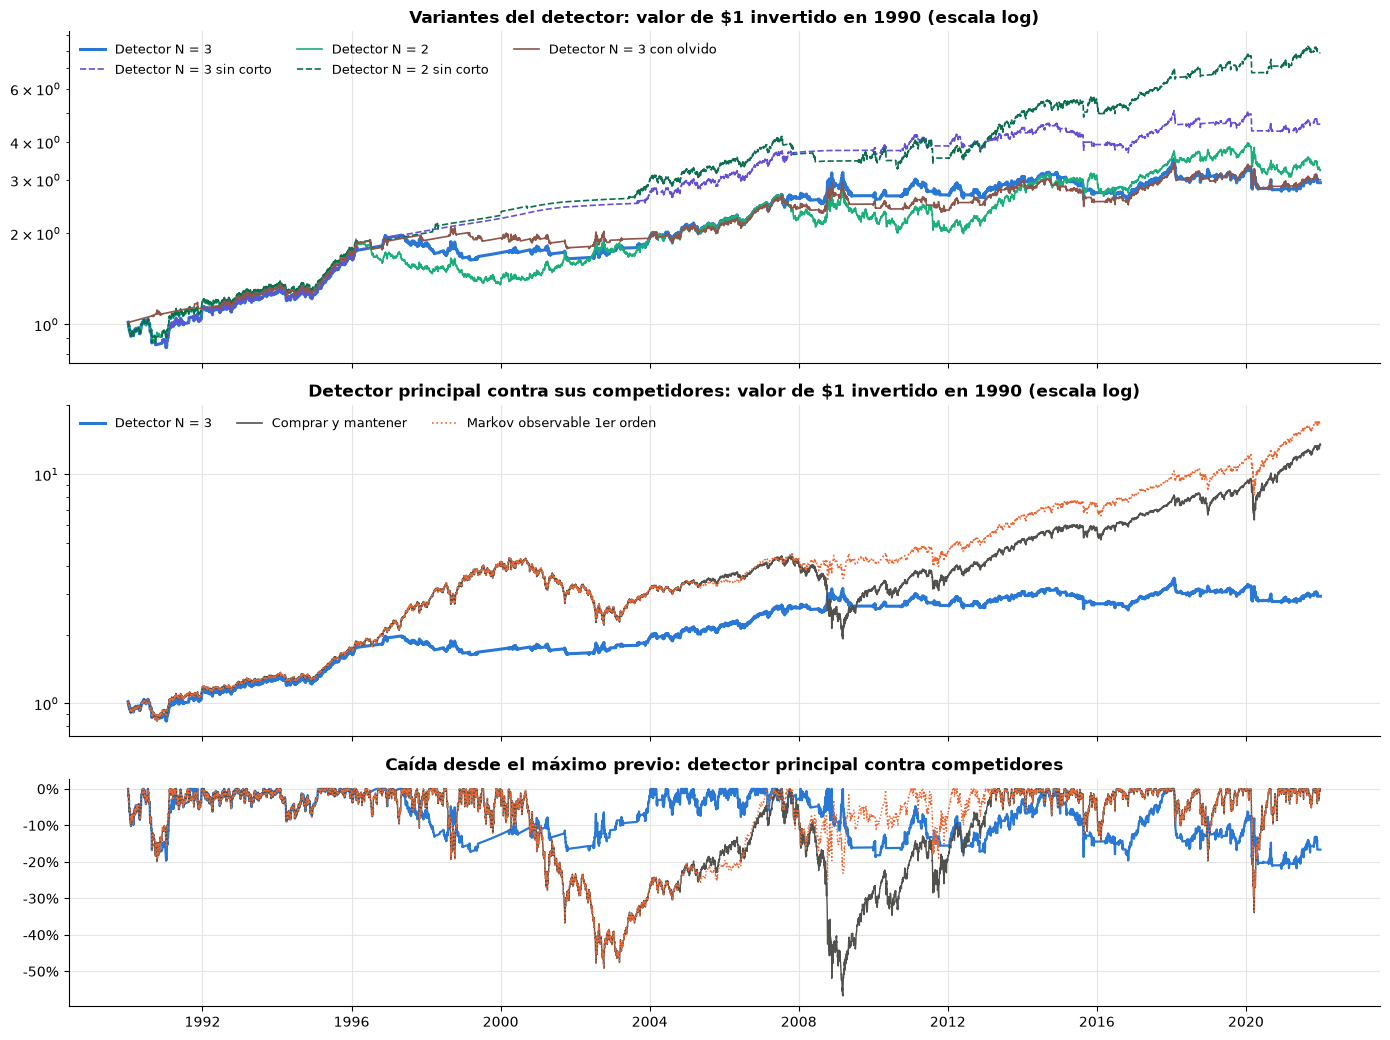

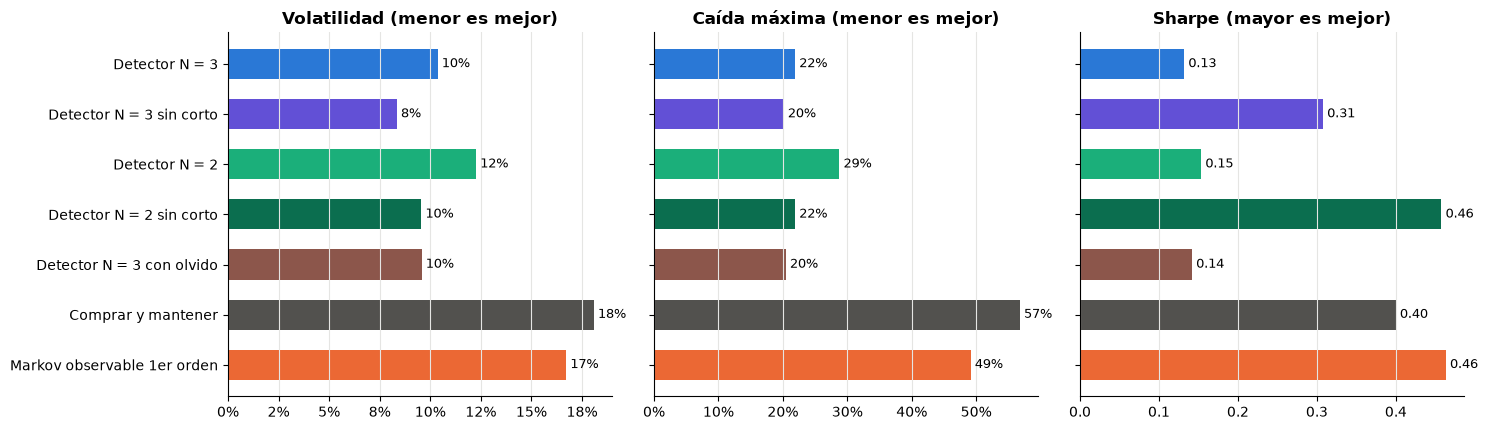

In [18]:
variantes_det = [n for n in res if n.startswith("Detector")]
competencia = ["Detector N = 3", "Comprar y mantener", "Markov observable 1er orden"]
fig, ax = plt.subplots(3, 1, figsize=(14, 10.5), sharex=True, gridspec_kw={"height_ratios": [1.6, 1.6, 1.1]})
for panel, grupo, titulo in [(0, variantes_det, "Variantes del detector: valor de $1 invertido en 1990 (escala log)"),
                             (1, competencia, "Detector principal contra sus competidores: valor de $1 invertido en 1990 (escala log)")]:
    for n in grupo:
        riqueza = (1 + res[n][0]).cumprod()
        ax[panel].plot(riqueza, color=C_EST[n], lw=2.2 if n == "Detector N = 3" else 1.2, label=n, ls=LS.get(n, "-"))
    ax[panel].set_yscale("log"); ax[panel].set_title(titulo); ax[panel].legend(loc="upper left", ncol=3, fontsize=9)
for n in competencia:
    riqueza = (1 + res[n][0]).cumprod()
    ax[2].plot(riqueza / riqueza.cummax() - 1, color=C_EST[n], lw=1.6 if n == "Detector N = 3" else 1.0, ls=LS.get(n, "-"))
ax[2].set_title("Caída desde el máximo previo: detector principal contra competidores"); ax[2].yaxis.set_major_formatter(pct)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
orden = list(res)
for a, col, tit in zip(ax, ["vol. anual", "caída máxima", "Sharpe"], ["Volatilidad (menor es mejor)", "Caída máxima (menor es mejor)", "Sharpe (mayor es mejor)"]):
    vals = tabla_res.loc[orden, col].abs() if col != "Sharpe" else tabla_res.loc[orden, col]
    b = a.barh(orden[::-1], vals[::-1], color=[C_EST[n] for n in orden[::-1]], height=0.6)
    a.bar_label(b, labels=[f"{v:.0%}" if col != "Sharpe" else f"{v:.2f}" for v in vals[::-1]], padding=3, fontsize=9)
    a.set_title(tit); a.grid(axis="y", visible=False)
    if col != "Sharpe": a.xaxis.set_major_formatter(pct)
for a in ax[1:]: a.set_yticklabels([])
plt.tight_layout(); plt.show()

**Lectura: riesgo contra rendimiento.**
- **Reduce el riesgo, como se esperaba:** volatilidad de 10.4% contra 18.1% y caída máxima de −21.9% contra −56.8%. Todas las variantes del detector de la tabla tienen caídas máximas de 20% a 29%, contra 49% a 57% de los competidores. Este resultado es robusto: no depende de la variante.
- **No mejora el Sharpe:** 0.13 contra 0.40. La diferencia (0.27) es menor que 2 errores estándar (0.36), así que, en rigor, tampoco se puede afirmar que lo empeore. Lo que sí es claro es el costo en rendimiento: 3.4% anual contra 8.5%. Un dólar se convierte en unos 3 contra unos 13.
- **¿Dónde se pierde?** La gráfica de valor acumulado lo muestra en dos tramos:
  1. **1996–2003:** el detector queda casi plano mientras el índice se duplica y luego cae. Se perdió el mercado alcista (P2: escala de la ventana) y, en corto durante 2000–2002, no ganó lo suficiente para compensar.
  2. **2009–2021:** el índice sube unas 6 veces desde su mínimo y el detector apenas se mueve, por llegar tarde a los rebotes y por los parpadeos hacia base (fuera del mercado).

  En 2008 el detector sí funciona: sube mientras el índice cae a la mitad.
- **El corto resta en todas las combinaciones:** sin corto, el Sharpe sube de 0.13 a 0.31 con N = 3 y de 0.15 a 0.46 con N = 2, y lo mismo pasa en las 21 parejas de la bitácora (P5).
- **N = 2 contra N = 3.** Con la regla sin corto, N = 2 tiene mejor Sharpe (0.46 contra 0.31) con menos de la mitad de los cambios de posición (75 contra 119). La diferencia (0.15) no es significativa, pero apunta en la misma dirección que P2: N = 2 es más estable.
- **La cadena de Markov observable empata o supera a todos los detectores** (Sharpe de 0.46). Pero lo hace estando invertida 90% del tiempo (casi comprar y mantener: su caída máxima es de −49.1%) y con 834 cambios de posición, unos 26 al año. Con costos de transacción, su ventaja sobre comprar y mantener probablemente desaparece (D.2).

### ¿De dónde viene el resultado?

Comportamiento del S&P 500 según el régimen detectado (fuera de muestra, con rezago):


,% de los días,rend. anual del índice,vol. anual del índice,EE rend. anual,IC 95% inferior,IC 95% superior
alcista,52.5%,7.3%,11.0%,2.7%,2.0%,12.6%
base,32.7%,10.5%,18.2%,5.6%,-0.6%,21.5%
bajista,14.8%,16.8%,32.4%,14.9%,-12.4%,45.9%


Promedio de los 16 episodios bajistas de P3:


,índice,detector,episodios en que el detector gana
durante el episodio,-9.2%,-2.8%,56.2%
3 meses después,5.8%,0.5%,25.0%


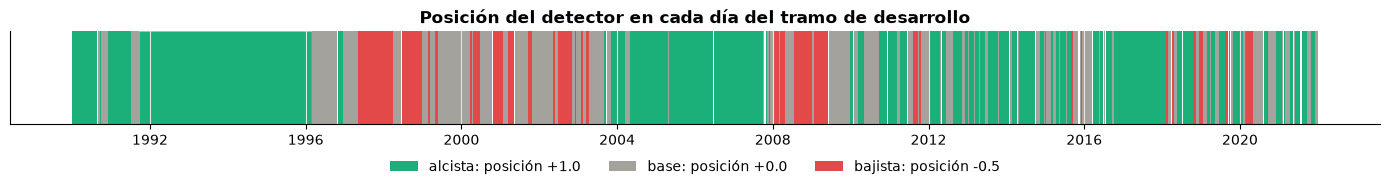

In [19]:
ret_det, _, w_det = res["Detector N = 3"]
reg_dia = pd.Series(prob[PRINCIPAL].values.argmax(1), index=prob[PRINCIPAL].index).shift(1 + CONFIG["rezago"]).reindex(w_det.index)
rs_des = r_simple[w_det.index]
por_reg = pd.DataFrame({n: {"% de los días": (reg_dia == i).mean(), "rend. anual del índice": rs_des[reg_dia == i].mean() * 252,
                            "vol. anual del índice": rs_des[reg_dia == i].std() * np.sqrt(252)}
                        for i, n in enumerate(NOMBRES)}).T
dias_reg = pd.Series({n: int((reg_dia == i).sum()) for i, n in enumerate(NOMBRES)})
por_reg["EE rend. anual"] = por_reg["vol. anual del índice"] / np.sqrt(dias_reg / 252)     # error estándar de la media anualizada
por_reg["IC 95% inferior"] = por_reg["rend. anual del índice"] - 1.96 * por_reg["EE rend. anual"]
por_reg["IC 95% superior"] = por_reg["rend. anual del índice"] + 1.96 * por_reg["EE rend. anual"]
print("Comportamiento del S&P 500 según el régimen detectado (fuera de muestra, con rezago):")
display(por_reg.style.format("{:.1%}"))

ret_bh = res["Comprar y mantener"][0]
acum = lambda r, a, b: (1 + r[a:b]).prod() - 1
filas = []
for _, e in ep_des.sort_values("inicio").iterrows():
    despues = ret_bh.index[ret_bh.index > e["fin"]][:63]
    filas.append({"episodio": f"{e['inicio']:%Y-%m} a {e['fin']:%Y-%m}",
                  "índice durante": acum(ret_bh, e["inicio"], e["fin"]), "detector durante": acum(ret_det, e["inicio"], e["fin"]),
                  "índice 3 meses después": acum(ret_bh, despues[0], despues[-1]) if len(despues) else np.nan,
                  "detector 3 meses después": acum(ret_det, despues[0], despues[-1]) if len(despues) else np.nan})
atrib = pd.DataFrame(filas).set_index("episodio")          # detalle por episodio (no se muestra)
resumen_ep = pd.DataFrame({
    "índice": [atrib["índice durante"].mean(), atrib["índice 3 meses después"].mean()],
    "detector": [atrib["detector durante"].mean(), atrib["detector 3 meses después"].mean()],
    "episodios en que el detector gana": [(atrib["detector durante"] > atrib["índice durante"]).mean(),
                                          (atrib["detector 3 meses después"] > atrib["índice 3 meses después"]).mean()]},
    index=["durante el episodio", "3 meses después"])
print(f"Promedio de los {len(atrib)} episodios bajistas de P3:")
display(resumen_ep.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(14, 2.2))
for val, n in zip(POS, NOMBRES):
    ax.fill_between(w_det.index, 0, 1, where=(w_det == val).values, color=C_REG[n], lw=0, label=f"{n}: posición {val:+.1f}")
ax.set_yticks([]); ax.set_ylim(0, 1); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
ax.set_title("Posición del detector en cada día del tramo de desarrollo"); plt.tight_layout(); plt.show()

**Lectura: de dónde viene el resultado.**
- **El detector identifica muy bien la volatilidad.** Fuera de muestra, la volatilidad del índice en cada régimen detectado queda perfectamente ordenada: 11.0%, 18.2% y 32.4%. Esa parte del modelo funciona.
- **Pero no identifica la dirección: el orden de los rendimientos se invierte.** El índice rindió 7.3% en régimen alcista, 10.5% en base y 16.8% en bajista. Sólo el del alcista tiene un intervalo de confianza que excluye el cero (2.0% a 12.6%); el del bajista va de −12.4% a +45.9%. Así que no se puede decir que el régimen bajista sea alcista. Lo defendible es que **no anticipa caídas**: después de un día volátil viene, en promedio, otro día volátil, no uno negativo. Además, los rebotes más fuertes ocurren dentro de regímenes volátiles (2009, 2020).
- **La regla supone una dirección que los datos no respaldan.** Pone 100% en el régimen donde el índice rindió menos (alcista, 7.3%), sale a T-bills en uno donde rindió más (base, 10.5%) y se pone en corto en el de mayor rendimiento promedio (bajista, 16.8%).
- **En las crisis, protege.** Durante los 16 episodios bajistas, el detector pierde en promedio −2.8% contra −9.2% del índice, y le gana en 56% de ellos.
- **En los rebotes, pierde casi todo lo que ganó.** En los 3 meses siguientes, el detector gana +0.5% contra +5.8% del índice, y le gana sólo en 25% de los episodios. Es el costo de la confirmación de 3 días y de la persistencia del régimen bajista: sale tarde de la defensa.

> **Respuesta a P4.** Sirve para **reducir el riesgo** (la volatilidad y la caída máxima bajan a la mitad o menos), pero no para mejorar el rendimiento ajustado por riesgo. La protección viene, como esperábamos, de estar fuera del mercado en las crisis. Pero se pierde por tres costos: (i) llegar tarde a los rebotes; (ii) un corto que apuesta a una dirección que el detector no anticipa; y (iii) clasificar como bajistas periodos que sólo eran volátiles para su ventana (1996–1999).

## P5. ¿Es suerte?

**Qué hacemos.** Juntamos en una **bitácora** todas las variantes de C.1, combinadas con 1, 3 o 5 días de confirmación y con o sin corto, más las cadenas de Markov observables de 1er y 2o orden. Se registran **todas**, no sólo la mejor, incluidas las que ya no se reportan en P2 a P4: ya se probaron, y quitarlas inflaría el resultado.

**Por qué.** Si se prueban muchas variantes, alguna va a tener un buen Sharpe por pura suerte (Bailey et al. [6]). Bailey y López de Prado [14] proponen dos correcciones:
- **PSR (Sharpe probabilístico):** la probabilidad de que el Sharpe verdadero sea mayor que 0, considerando cuántos días hay y qué tan frecuentes son los días extremos.
- **DSR (Sharpe deflactado):** la probabilidad de que el Sharpe supere al **mejor Sharpe que se esperaría por suerte** después de todas las pruebas. Ese umbral sube con el número de pruebas y con qué tan distintos son sus resultados. Como las variantes se parecen entre sí, se cuenta el número de pruebas *efectivamente independientes*. El criterio usual es DSR > 0.95.

**Qué esperamos.** Que el Sharpe de la regla principal sobreviva a la corrección. Reducir el riesgo (P4) y tener un buen rendimiento por unidad de riesgo son dos resultados distintos, y se reportan por separado [14].

**La regla que se evalúa es la principal, fijada de antemano, no la mejor de la bitácora.**

In [20]:
bitacora, excesos = [], {}
for nombre_v in prob:
    base_pos = POS if prob[nombre_v].shape[1] == 3 else POS2
    for k in [1, 3, 5]:
        for corto in ["con corto", "sin corto"]:
            posiciones = base_pos if corto == "con corto" else sin_corto(base_pos)
            prueba = f"HMM {nombre_v} | k={k} | {corto}"
            ret, ex, w = evaluar(posicion_detector(prob[nombre_v], k, posiciones), ini, fin)
            excesos[prueba] = ex
            bitacora.append({"prueba": prueba, "k": k, "corto": corto,
                             "principal": nombre_v == PRINCIPAL and k == CONFIG["dias_confirmacion"] and corto == "con corto",
                             **metricas(ret, ex, w)})
for n_, orden_ in [("Markov observable 1er orden", 1), ("Markov observable 2o orden", 2)]:
    r_m = res[n_] if n_ in res else evaluar(posicion_markov(orden_), ini, fin)
    excesos[n_] = r_m[1]
    bitacora.append({"prueba": n_, "k": np.nan, "corto": "—", "principal": False, **metricas(*r_m)})
bitacora = pd.DataFrame(bitacora).set_index("prueba")
excesos = pd.DataFrame(excesos)
principal = bitacora.index[bitacora["principal"]][0]
print(f"{len(bitacora)} pruebas registradas. Regla principal: {principal}")
# Resumen por tipo de prueba (la bitácora completa queda en la variable `bitacora`)
tipo = bitacora["corto"].map({"con corto": "detector con corto", "sin corto": "detector sin corto", "—": "Markov observable"})
bitacora.groupby(tipo)["Sharpe"].describe()[["count", "min", "50%", "max"]].rename(
    columns={"count": "pruebas", "min": "Sharpe mín.", "50%": "Sharpe mediano", "max": "Sharpe máx."}).style.format(
    {"pruebas": "{:.0f}", "Sharpe mín.": "{:.2f}", "Sharpe mediano": "{:.2f}", "Sharpe máx.": "{:.2f}"})

44 pruebas registradas. Regla principal: HMM t | N=3 | W=2000 | k=3 | con corto


,pruebas,Sharpe mín.,Sharpe mediano,Sharpe máx.
corto,,,,
Markov observable,2,0.34,0.40,0.46
detector con corto,21,0.05,0.13,0.23
detector sin corto,21,0.21,0.31,0.52


Sharpe deflactado de la regla principal en el tramo de desarrollo:
         Sharpe diario: 0.0083
          Sharpe anual: 0.1319
           pruebas (M): 44.0000
     correlación media: 0.6600
     pruebas efectivas: 15.6202
     umbral SR0 diario: 0.0132
      PSR (Sharpe > 0): 0.7719
                   DSR: 0.3299
Lugar de la regla principal por Sharpe: 34 de 44


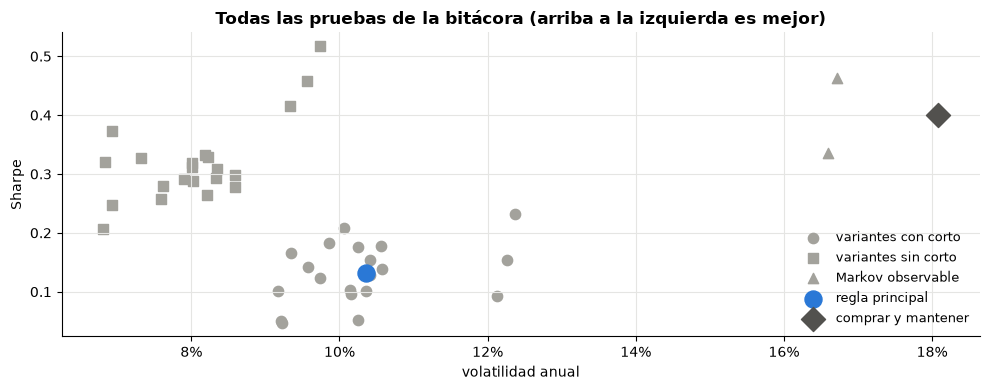

In [21]:
dsr = sharpe_deflactado(excesos[principal], excesos)
print("Sharpe deflactado de la regla principal en el tramo de desarrollo:")
for k, v in dsr.items():
    print(f"  {k:>20}: {v:,.4f}")
lugar = int((bitacora["Sharpe"] > bitacora.loc[principal, "Sharpe"]).sum()) + 1
print(f"Lugar de la regla principal por Sharpe: {lugar} de {len(bitacora)}")

bh = tabla_res.loc["Comprar y mantener"]
fig, ax = plt.subplots(figsize=(10, 4))
for corto, marca in [("con corto", "o"), ("sin corto", "s"), ("—", "^")]:
    sub = bitacora[bitacora["corto"] == corto]
    ax.scatter(sub["vol. anual"], sub["Sharpe"], marker=marca, s=55, color="#a3a29c",
               label="Markov observable" if corto == "—" else f"variantes {corto}")
ax.scatter(bitacora.loc[principal, "vol. anual"], bitacora.loc[principal, "Sharpe"], s=150, color=C_EST["Detector N = 3"], label="regla principal", zorder=3)
ax.scatter(bh["vol. anual"], bh["Sharpe"], s=150, marker="D", color=C_EST["Comprar y mantener"], label="comprar y mantener", zorder=3)
ax.xaxis.set_major_formatter(pct); ax.set_xlabel("volatilidad anual"); ax.set_ylabel("Sharpe")
ax.set_title("Todas las pruebas de la bitácora (arriba a la izquierda es mejor)"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

**Lectura.**
- **El Sharpe de la regla principal no sobrevive a la corrección:** Sharpe deflactado de 0.33, lejos del criterio de 0.95. Ni siquiera sin corregir por número de pruebas es convincente: la probabilidad de que su Sharpe sea positivo es de 0.77.
- **Las pruebas se parecen mucho entre sí** (correlación media de 0.66), así que 44 pruebas equivalen a unas 15.6 independientes. El umbral de suerte resultante es un Sharpe anual de unos 0.21 ($0.0132 \times \sqrt{252}$).
- **La regla principal queda en el lugar 34 de 44.** Las mejores son las variantes sin corto y con N = 2. La mejor de todas (N = 2, k = 5, sin corto, Sharpe de 0.52) pasaría ese umbral por aproximadamente 1.7 errores estándar. Pero se encontró **después** de ver los resultados, que es exactamente el sesgo que corrige el Sharpe deflactado [6], [14]. Por eso no puede reportarse como resultado: cualquier regla que se adopte a partir de aquí se declara antes y se evalúa una sola vez en el tramo reservado.
- **La dispersión de la bitácora es informativa en sí misma:** con corto, los Sharpe van de 0.05 a 0.23; sin corto, de 0.21 a 0.52. Quitar el corto mejora todas las variantes, sin excepción. Es una conclusión robusta, no una prueba elegida.

> **Respuesta a P5.** Con la regla principal, el Sharpe es indistinguible de la suerte. Lo que sí es robusto en toda la bitácora es (i) la reducción del riesgo y (ii) que el corto resta.

# D. Resumen de hallazgos, diagnóstico y tramo reservado
## D.1 Resumen de hallazgos (tramos de estimación y desarrollo)

Lo que esperábamos según las lecturas contra lo que encontramos. La tabla se llena sola con los resultados de esta corrida; es la base del Reporte 4.

In [22]:
t_sel = tabla_sel.set_index(["distribución", "N"])
mejor = tabla_sel.loc[tabla_sel["BIC"].idxmin()]
reg = tabla_regimenes(modelo_est)
e_p, e_o = estab.loc["Detector N = 3 (ventana 2,000)"], estab.loc["N = 3 con olvido"]
ef = efecto.loc["Detector N = 3 (ventana 2,000)"]
det, bh, sc = tabla_res.loc["Detector N = 3"], tabla_res.loc["Comprar y mantener"], tabla_res.loc["Detector N = 3 sin corto"]
n2, n2sc = tabla_res.loc["Detector N = 2"], tabla_res.loc["Detector N = 2 sin corto"]
lista = lambda s, f: ", ".join(f"{n} {v:{f}}" for n, v in s.items())

hallazgos = pd.DataFrame([
    {"pregunta": "P1. ¿Qué modelo?",
     "esperábamos": "La t con N = 3 describe bien los datos y sus regímenes tienen sentido económico [4], [11]",
     "encontramos": f"Con N = 3, la t le gana a la normal por {t_sel.loc[('normal', 3), 'BIC'] - t_sel.loc[('t', 3), 'BIC']:,.0f} puntos de BIC. "
                    f"El menor BIC es {mejor['distribución']} con N = {mejor['N']} (estabilidad {mejor['estabilidad']:.0%}, "
                    f"régimen más corto de {mejor['duración mínima (días)']:.1f} días). Rendimiento anual por régimen: {lista(reg['rend. anual'], '+.1%')}. "
                    f"Viterbi: {cambios['t']} cambios de régimen con la t contra {cambios['normal']} con la normal. "
                    f"Memoria de la volatilidad reproducida: {memoria['t']:.0%} (t) contra {memoria['normal']:.0%} (normal)."},
    {"pregunta": "P2. ¿Estables en tiempo real?",
     "esperábamos": "Los parámetros cambian; el olvido los suaviza [12]",
     "encontramos": f"Volatilidad bajista entre {e_p['vol. bajista mín.']:.0%} y {e_p['vol. bajista máx.']:.0%}; el orden coincide en "
                    f"{e_p['orden coincide']:.0%} de las reestimaciones ({e_o['orden coincide']:.0%} con olvido; salto promedio "
                    f"{e_p['salto promedio']:.1%} contra {e_o['salto promedio']:.1%}). La etiqueta del día anterior cambia sólo por reestimar en "
                    f"{ef['salto de etiqueta']:.0%} de las reestimaciones, y {ef['% cerca de una reestimación']:.0%} de los cambios de posición "
                    f"caen en los {k_conf} días tras reestimar (esperado {ef['% esperado sin efecto']:.0%}; unos {ef['cambios atribuibles a reestimar']:.0f} "
                    f"cambios atribuibles). Orden coincide: {por_ventana['orden coincide'].iloc[0]:.0%} con pocas crisis en la ventana contra "
                    f"{por_ventana['orden coincide'].iloc[-1]:.0%} con muchas."},
    {"pregunta": "P3. ¿Qué tan rápido detecta?",
     "esperábamos": "Con retraso [7]",
     "encontramos": f"Detecta {int(ep_des['detectado'].sum())} de {len(ep_des)} episodios bajistas, con un retraso mediano de "
                    f"{np.nanmedian(retrasos):.0f} días hábiles (máximo {np.nanmax(retrasos):.0f}). Coincide con Viterbi {coincide:.0%} de los días."},
    {"pregunta": "P4. ¿Sirve para invertir y por qué?",
     "esperábamos": "Reduce el riesgo, porque sale del mercado en las crisis [5], [9]",
     "encontramos": f"Volatilidad {det['vol. anual']:.1%} contra {bh['vol. anual']:.1%}; caída máxima {det['caída máxima']:.1%} contra "
                    f"{bh['caída máxima']:.1%}. Sharpe {det['Sharpe']:.2f} contra {bh['Sharpe']:.2f} (EE {det['EE Sharpe']:.2f}); sin corto "
                    f"{sc['Sharpe']:.2f}; N = 2 {n2['Sharpe']:.2f} ({n2sc['Sharpe']:.2f} sin corto). Durante las crisis "
                    f"{resumen_ep.loc['durante el episodio', 'detector']:+.1%} contra {resumen_ep.loc['durante el episodio', 'índice']:+.1%}; "
                    f"3 meses después {resumen_ep.loc['3 meses después', 'detector']:+.1%} contra {resumen_ep.loc['3 meses después', 'índice']:+.1%}. "
                    f"Rendimiento anual del índice según el régimen detectado: {lista(por_reg['rend. anual del índice'], '+.1%')}."},
    {"pregunta": "P5. ¿Es suerte?",
     "esperábamos": "El Sharpe sobrevive a la corrección [14]",
     "encontramos": f"Sharpe deflactado {dsr['DSR']:.2f} y probabilidad de Sharpe positivo {dsr['PSR (Sharpe > 0)']:.2f}, con "
                    f"{dsr['pruebas (M)']:.0f} pruebas ({dsr['pruebas efectivas']:.1f} efectivas). La regla principal queda en el lugar "
                    f"{lugar} de {len(bitacora)} por Sharpe."},
]).set_index("pregunta")
hallazgos.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,esperábamos,encontramos
pregunta,,
P1. ¿Qué modelo?,"La t con N = 3 describe bien los datos y sus regímenes tienen sentido económico [4], [11]","Con N = 3, la t le gana a la normal por 43 puntos de BIC. El menor BIC es t con N = 4 (estabilidad 60%, régimen más corto de 3.3 días). Rendimiento anual por régimen: alcista +22.7%, base +5.9%, bajista -16.8%. Viterbi: 142 cambios de régimen con la t contra 215 con la normal. Memoria de la volatilidad reproducida: 57% (t) contra 49% (normal)."
P2. ¿Estables en tiempo real?,Los parámetros cambian; el olvido los suaviza [12],"Volatilidad bajista entre 16% y 54%; el orden coincide en 65% de las reestimaciones (58% con olvido; salto promedio 0.7% contra 0.5%). La etiqueta del día anterior cambia sólo por reestimar en 4% de las reestimaciones, y 14% de los cambios de posición caen en los 3 días tras reestimar (esperado 14%; unos -1 cambios atribuibles). Orden coincide: 9% con pocas crisis en la ventana contra 100% con muchas."
P3. ¿Qué tan rápido detecta?,Con retraso [7],"Detecta 13 de 16 episodios bajistas, con un retraso mediano de 5 días hábiles (máximo 52). Coincide con Viterbi 63% de los días."
P4. ¿Sirve para invertir y por qué?,"Reduce el riesgo, porque sale del mercado en las crisis [5], [9]","Volatilidad 10.4% contra 18.1%; caída máxima -21.9% contra -56.8%. Sharpe 0.13 contra 0.40 (EE 0.18); sin corto 0.31; N = 2 0.15 (0.46 sin corto). Durante las crisis -2.8% contra -9.2%; 3 meses después +0.5% contra +5.8%. Rendimiento anual del índice según el régimen detectado: alcista +7.3%, base +10.5%, bajista +16.8%."
P5. ¿Es suerte?,El Sharpe sobrevive a la corrección [14],"Sharpe deflactado 0.33 y probabilidad de Sharpe positivo 0.77, con 44 pruebas (15.6 efectivas). La regla principal queda en el lugar 34 de 44 por Sharpe."


**Nota sobre la tabla.** En P2, "unos −1 cambios atribuibles" significa que **no hay exceso**: hubo un cambio de posición menos que lo esperado por azar en los 3 días tras reestimar.

## D.2 Diagnóstico final

### Qué funciona
1. **El modelo dentro de muestra:** la t con N = 3 es estable, persistente y económicamente interpretable en 1950–1989 (P1).
2. **El detector como medidor de volatilidad:** fuera de muestra separa días de 11%, 18% y 32% de volatilidad anual (P4). Es la parte más sólida del prototipo.
3. **La reducción del riesgo:** la volatilidad y la caída máxima bajan a la mitad o menos en todas las variantes (P4, P5).
4. **El protocolo:** tramo reservado intacto, decisiones fijas, bitácora completa y corrida reproducible (la huella de los datos y el Sharpe deflactado coinciden con la v4).

### Qué no funciona, en orden de importancia

| # | Problema | Evidencia | Dónde nace |
|---|---|---|---|
| 1 | **Las etiquetas son relativas a la ventana.** Sin crisis en la ventana, "bajista" significa "el menos tranquilo de estos 2,000 días" | Orden coincide en 9% con pocas crisis contra 100% con muchas; volatilidad bajista de 16% a 54%; mercado alcista de 1996–1999 clasificado como bajista; corrección de 1990 no detectada (P2, P3) | `ordenar()` ordena por volatilidad **dentro de cada ventana**, y `prueba_movil()` reestima la escala completa cada vez |
| 2 | **La regla traduce volatilidad en dirección.** Detecta volatilidad, pero invierte como si detectara pérdidas | Rendimiento del índice por régimen: +7.3% / +10.5% / +16.8%; el corto resta en las 21 parejas (P4, P5) | `CONFIG["posicion"]` = {1, 0, −0.5} y `posicion_detector()` |
| 3 | **Sale tarde de la defensa.** Pierde los rebotes | +0.5% contra +5.8% en los 3 meses tras una crisis; sólo gana en 25% de los episodios (P4) | La confirmación simétrica de 3 días en `posicion_detector()` y la persistencia del régimen bajista |
| 4 | **Poco poder estadístico para comparar Sharpe** | Error estándar de 0.18 en 32 años: diferencias menores a unos 0.36 no se distinguen (P4, P5) | La métrica, no el modelo: la regla de 2 errores estándar no aprovecha que las estrategias están correlacionadas |
| 5 | **Rendimientos sin costos** | 177 cambios de posición en 32 años (unos 5.5 al año) en el detector y 834 (unos 26 al año) en la cadena de Markov | `evaluar()` no descuenta costos |

**Lo que se descartó con evidencia:**
- **El ruido de la reestimación no es un problema:** el régimen más probable cambia sólo por reestimar en 4% de las reestimaciones, y no hay exceso de cambios de posición (P2).
- **El modelo semi-Markov no mejoró el BIC** (v4).
- **El olvido exponencial suaviza, pero no ancla la escala** (P2).

### Consideraciones antes de cambiar nada
- **El tramo de desarrollo ya está "visto".** Cualquier regla nueva elegida porque funcionó en 1990–2021 está sesgada. El camino limpio:
  1. declarar **una** regla principal nueva en el Reporte 4, con su justificación teórica (no su Sharpe);
  2. correrla en el desarrollo sólo como diagnóstico, agregando todas sus variantes a la bitácora (M crece y el Sharpe deflactado se recalcula);
  3. evaluarla **una sola vez** en el tramo reservado.
- **La referencia de crisis (Viterbi) también es un modelo.** Usa una sola escala para 1950–2021 y toda la historia. Sirve para comparar, pero las métricas de detección (P3) miden acuerdo con ese modelo, no con una "verdad".
- **El objetivo del producto debe quedar explícito.** Si es reducir el riesgo, el detector ya cumple y conviene evaluarlo por volatilidad, caída máxima y costo en rendimiento. Si es superar a comprar y mantener en Sharpe, 32 años de datos no alcanzan para demostrarlo con diferencias pequeñas.
- **Hay que revisar el cambio propuesto en el plan.** El filtro de Kalman se pensó para suavizar los parámetros entre reestimaciones, y P2 muestra que ese no es el problema. Peor aún: un Kalman que siga los parámetros más de cerca haría los regímenes **más** locales, lo contrario de lo que hace falta. Sólo tendría sentido un Kalman cuyos parámetros regresen hacia un nivel de largo plazo, y eso equivale a la propuesta B, con más complejidad.

### Propuestas de mejora

| | Propuesta | Problema que ataca | Dónde se implementa | Cómo se mide | Costo |
|---|---|---|---|---|---|
| **A** | **Etiquetas ancladas a una escala fija** | 1, y en parte 3 | Nueva función `etiquetar_anclado(m, ref)` en lugar de `ordenar()` dentro de `prueba_movil()` | Orden por tercio de crisis (P2), 1990 y 1996–1999 (P3), P4 | Bajo |
| **B** | **Parámetros encogidos hacia un ancla de largo plazo** | 1 | Paso M de `ajustar_hmm()` | Rango de la volatilidad bajista y orden por tercio (P2) | Medio |
| **C** | **Regla por volatilidad pronosticada** (volatility targeting) | 2, y elimina la dependencia de las etiquetas | Nueva `posicion_volatilidad()` junto a `posicion_detector()` | P4 completo; P5 con la bitácora ampliada | Bajo |
| **D** | **Sin corto, y la base invertida en lugar de en T-bills** | 2 | `CONFIG["posicion"]` | P4 | Mínimo |
| **E** | **Confirmación asimétrica:** lenta para salir, rápida para volver | 3 | `posicion_detector()`: `k_salida = 3`, `k_entrada = 1` | Rendimiento en los 3 meses tras una crisis (P4) | Mínimo |
| **F** | **Costos de transacción** | 5 | `evaluar()`: restar $c\,\lvert\Delta w_t\rvert$, con c = 5 y 10 pb | Tabla de P4 con costos | Mínimo |
| **G** | **Comparación pareada de Sharpe** | 4 | Nueva función junto a `ee_sharpe()`: prueba de Ledoit y Wolf [16] o bootstrap por bloques de la diferencia de rendimientos | P4 y P5 | Bajo |

**Cómo funcionaría cada una:**
- **A. Etiquetas ancladas.** Después de cada reestimación, cada régimen recibe la etiqueta del régimen de referencia (el modelo de 1950–1989: 6.9%, 11.9% y 22.6% de volatilidad) más cercano en escala logarítmica. Equivale a umbrales fijos de unos 9% y 16% anual (las medias geométricas entre regímenes vecinos). Dos regímenes pueden recibir la misma etiqueta, y un régimen "bajista" tranquilo deja de serlo. Los umbrales se fijan con 1950–1989, **no** se ajustan con el desarrollo. Conserva la explicabilidad de alcista, base y bajista.
- **B. Ancla de largo plazo.** Se estima con "pseudo-días" de referencia: $\sigma_i^2 = \dfrac{\sum_t \gamma_i(t)u_i(t)(x_t-\mu_i)^2 + \kappa\,\sigma_{i,\text{ref}}^2}{\sum_t \gamma_i(t) + \kappa}$, y lo mismo para $\mu_i$. Con κ = 0 es el modelo actual; con κ grande, los parámetros quedan fijos en la referencia. Es la versión con fundamento estadístico de A, y es lo que haría un Kalman que regrese hacia un nivel de largo plazo.
- **C. Volatilidad pronosticada.** Usa el detector para lo que mejor hace. Con la probabilidad de mañana, $\hat p_{t+1} = \alpha_t A$, se calcula la varianza de la mezcla, $\hat\sigma^2_{t+1} = \sum_i \hat p_i(\sigma_i^{2}+\mu_i^2) - \big(\sum_i \hat p_i \mu_i\big)^2$, con $\sigma_i$ la desviación estándar del régimen (`desv_estandar`). La posición es $w_t = \min\!\big(1,\ \sigma^*/\hat\sigma_{t+1}\big)$, con $\sigma^*$ fijado de antemano (por ejemplo, la volatilidad de 1950–1989, 13.5%). No necesita etiquetas ni supone una dirección. Tiene sustento en la literatura de portafolios gestionados por volatilidad (Moreira y Muir [15]).
- **D y E** son cambios de una línea, y la evidencia ya los apoya (el corto resta en las 21 parejas y el detector gana sólo 25% de los rebotes). Pero deben declararse antes de evaluarse en el tramo reservado.
- **F** es una consideración más que una mejora. El orden de magnitud: con 10 pb por unidad de posición cambiada, el detector perdería alrededor de 0.5 puntos porcentuales al año, y la cadena de Markov unos 2.6, más que su ventaja en rendimiento sobre comprar y mantener (0.8 puntos). Hay que medirlo, no suponerlo.

**Qué se descarta:** el modelo semi-Markov, ventanas más largas o más cortas elegidas por su resultado (serían otra prueba de la bitácora, no una corrección del mecanismo) y un Kalman que siga los parámetros sin un ancla.

## D.3 Bases para el Reporte 4

**Hallazgos que sostienen el reporte:**
1. El modelo de 1950–1989 es bueno y fácil de interpretar (P1).
2. En tiempo real, el detector mide bien la volatilidad (P4), pero sus etiquetas dependen de la ventana (P2): es la causa principal de su desempeño en 1990–2001.
3. Reduce el riesgo a la mitad, pero no mejora el Sharpe, por la regla direccional y los rebotes perdidos (P4). Su Sharpe no sobrevive a la corrección (P5).

**Cambio propuesto recomendado:**
- **Principal:** **A, etiquetas ancladas**, con la regla **D sin corto**. Ataca la causa principal medida en P2, mantiene los tres regímenes explicables y se implementa en una función.
- **Competidor:** **C, regla por volatilidad pronosticada**. Responde a otra pregunta: si el detector sólo ve volatilidad, ¿vale más usarlo como medidor de volatilidad que como clasificador?
- **Siempre:** F (costos) y G (comparación pareada).

**Lectura principal sugerida para el reporte:** Moreira y Muir [15], si el eje es la regla por volatilidad. Si el eje es el anclaje de parámetros, una lectura sobre estimación con información previa (Bayes o máxima verosimilitud penalizada) en HMM. Cualquiera de las dos sustituye a Kalman como artículo principal con mejor apoyo en la evidencia.

**Qué hay que declarar en el reporte:**
- el reenfoque de diez a cinco preguntas;
- las desviaciones del Reporte 3 (reestimaciones que parten de la anterior con dos arranques extra cada 6 meses; el semi-Markov sólo estima duraciones; la referencia de Viterbi con 4 arranques);
- que los cambios se eligieron después de ver el desarrollo y por eso se evaluarán sólo en el tramo reservado.

## D.4 Tramo reservado (2022 – septiembre 2026)

**Qué hace.** Evalúa **una sola vez** la regla principal, ya fija, con datos que nunca se usaron para tomar ninguna decisión [6]. Sólo corre con `EVALUAR_RESERVADO = True`.

**Reglas.** Si después de abrirlo se cambia cualquier cosa de `CONFIG` y se vuelve a correr, este tramo deja de ser un examen limpio y hay que declararlo.

In [23]:
if EVALUAR_RESERVADO:
    ini_r, fin_r = fechas[i_res], fechas[-1]
    res_r = {n: evaluar(s, ini_r, fin_r) for n, s in senales.items()}
    tabla_r = pd.DataFrame({n: metricas(*v) for n, v in res_r.items()}).T
    ex_r = res_r["Detector N = 3"][1]
    sr = ex_r.mean() / ex_r.std()
    psr_r = stats.norm.cdf(sr * np.sqrt(len(ex_r) - 1) /
                           np.sqrt(1 - stats.skew(ex_r) * sr + (stats.kurtosis(ex_r, fisher=False) - 1) / 4 * sr ** 2))
    print(f"Tramo reservado {ini_r:%Y-%m-%d} a {fin_r:%Y-%m-%d} ({len(ex_r)} días) | PSR de la regla principal: {psr_r:.3f}")
    display(tabla_r.style.format(FMT_RES))
    fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1.2]})
    for n, (ret, _, _) in res_r.items():
        ax[0].plot((1 + ret).cumprod(), color=C_EST[n], lw=2.2 if n == "Detector N = 3" else 1.0, label=n,
                   ls=LS.get(n, "-"))
    ax[0].set_title("Valor de $1 invertido, tramo reservado"); ax[0].legend(loc="upper left", ncol=3, fontsize=9)
    pr = prob[PRINCIPAL][ini_r:]
    ax[1].stackplot(pr.index, pr.T.values, colors=[C_REG[n] for n in NOMBRES], labels=NOMBRES, alpha=0.85, lw=0)
    ax[1].set_ylim(0, 1); ax[1].legend(loc="upper left", ncol=3); ax[1].set_title("Probabilidad filtrada de cada régimen")
    plt.tight_layout(); plt.show()
else:
    print("Tramo reservado BLOQUEADO: no se calculó ninguna probabilidad ni resultado después de "
          f"{fechas[i_res - 1]:%Y-%m-%d}.")

Tramo reservado BLOQUEADO: no se calculó ninguna probabilidad ni resultado después de 2021-12-31.


## D.5 Guardar resultados para el v6

Guarda todo lo que el notebook v6 necesita para no volver a estimar: las probabilidades filtradas y los parámetros de **todas** las variantes (para recalcular la bitácora con costos), la bitácora y sus excesos (para el Sharpe deflactado con 44 + n pruebas), el modelo de 1950–1989 (para los umbrales anclados) y los episodios de Viterbi (para medir la detección). El archivo queda junto al notebook.

In [24]:
import pickle
assert not EVALUAR_RESERVADO, "No guardes con el reservado abierto: el v6 debe partir del tramo bloqueado"
guardar = {
    "version": "v5.1", "huella": huella, "CONFIG": CONFIG, "DIST": DIST, "OTRA": OTRA,
    "PRINCIPAL": PRINCIPAL, "VARIANTES": VARIANTES,
    "prob": prob, "params": params,                     # todas las variantes, sólo hasta 2021 si el reservado está bloqueado
    "bitacora": bitacora, "excesos": excesos, "principal_bitacora": principal,
    "modelo_est": modelo_est,                           # HMM t, N = 3, estimado con 1950–1989
    "ruta": ruta, "episodios": episodios,               # Viterbi con toda la historia hasta 2021 (referencia de crisis)
    "dsr": dsr, "evaluar_reservado": EVALUAR_RESERVADO,
}
with open("resultados_v5.pkl", "wb") as f:
    pickle.dump(guardar, f)
print(f"Guardado resultados_v5.pkl | huella {huella} | {len(bitacora)} pruebas en la bitácora | "
      f"DSR de la regla principal {dsr['DSR']:.2f} | variantes con probabilidades: {len(prob)}")


Guardado resultados_v5.pkl | huella ab3ae2b8c6 | 44 pruebas en la bitácora | DSR de la regla principal 0.33 | variantes con probabilidades: 7


## Bibliografía

[1] L. R. Rabiner, "A tutorial on hidden Markov models and selected applications in speech recognition," *Proceedings of the IEEE*, vol. 77, no. 2, pp. 257–286, 1989. http://www.cs.ubc.ca/~murphyk/Bayes/rabiner.pdf

[2] J. D. Hamilton, "Macroeconomic regimes and regime shifts," in *Handbook of Macroeconomics*, vol. 2A, pp. 163–201, 2016. https://www.nber.org/system/files/working_papers/w21863/w21863.pdf

[3] J. A. Bilmes, "A gentle tutorial of the EM algorithm and its application to parameter estimation for Gaussian mixture and hidden Markov models," ICSI, TR-97-021, 1998. https://www.cs.cmu.edu/~aarti/Class/10701/readings/gentle_tut_HMM.pdf

[4] J. Pohle, R. Langrock, F. M. van Beest y N. M. Schmidt, "Selecting the number of states in hidden Markov models," *JABES*, vol. 22, no. 3, pp. 270–293, 2017. https://arxiv.org/pdf/1701.08673

[5] P. Nystrup, H. Madsen y E. Lindström, "Dynamic portfolio optimization across hidden market regimes," *Quantitative Finance*, vol. 18, no. 1, pp. 83–95, 2018. https://backend.orbit.dtu.dk/ws/files/152802375/phd465_Nystrup_P.pdf

[6] D. H. Bailey, J. M. Borwein, M. López de Prado y Q. J. Zhu, "Pseudo-mathematics and financial charlatanism," *Notices of the AMS*, vol. 61, no. 5, pp. 458–471, 2014. https://www.ams.org/journals/notices/201405/rnoti-p458.pdf

[7] Z. Liu y S. Wang, "Decoding Chinese stock market returns: Three-state hidden semi-Markov model," *Pacific-Basin Finance Journal*, vol. 44, pp. 127–149, 2017. https://ssrn.com/abstract=2827838

[8] J. A. Climent Hernández, D. Rodríguez Benavides y R. Y. Castillo Dieguez, "Ingeniería financiera y portafolios óptimos con cambio de régimen," *REMEF*, vol. 20, no. 4, e1419, 2025. https://remef.org.mx/index.php/remef/article/view/1419

[9] J. Bulla, S. Mergner, I. Bulla, A. Sesboüé y C. Chesneau, "Markov-switching asset allocation: Do profitable strategies exist?," *Journal of Asset Management*, vol. 12, no. 5, pp. 310–321, 2011. https://mpra.ub.uni-muenchen.de/21154/

[10] J. M. Gómez R. y J. A. Jiménez M., "Selección óptima de portafolios basada en cadenas de Markov de primer y segundo orden," *Lecturas de Economía*, no. 92, pp. 33–66, 2020. https://www.redalyc.org/journal/1552/155260967005/html/

[11] J. Bulla, "Hidden Markov models with t components. Increased persistence and other aspects," *Quantitative Finance*, vol. 11, no. 3, pp. 459–475, 2011. https://mpra.ub.uni-muenchen.de/21830/1/MPRA_paper_21830.pdf

[12] P. Nystrup, H. Madsen y E. Lindström, "Long memory of financial time series and hidden Markov models with time-varying parameters," *Journal of Forecasting*, vol. 36, no. 8, pp. 989–1002, 2017. https://orbit.dtu.dk/files/125919765/Long_memory_and_time_varying_parameters_ACCEPTED_VERSION.pdf

[13] J.-O. Koslik, "Hidden semi-Markov models with inhomogeneous state dwell-time distributions," arXiv:2405.13553, 2024. https://arxiv.org/pdf/2405.13553

[14] D. H. Bailey y M. López de Prado, "The deflated Sharpe ratio," *Journal of Portfolio Management*, vol. 40, no. 5, pp. 94–107, 2014. http://www.davidhbailey.com/dhbpapers/deflated-sharpe.pdf

[15] A. Moreira y T. Muir, "Volatility-managed portfolios," *Journal of Finance*, vol. 72, no. 4, pp. 1611–1644, 2017. Versión de trabajo: NBER Working Paper 22208. https://www.nber.org/papers/w22208

[16] O. Ledoit y M. Wolf, "Robust performance hypothesis testing with the Sharpe ratio," *Journal of Empirical Finance*, vol. 15, no. 5, pp. 850–859, 2008.